# Previsão de Ingressantes e Análise da Evasão por Curso no IFCE
## Notebook único de reprodução dos resultados do TCC

**Autor:** Cleiton Barbosa Valente · **Orientador:** Prof. Alexandro Lima Damasceno · IFCE, *campus* Aracati

Este notebook reproduz, de ponta a ponta, todas as tabelas e figuras da Seção 5 (Resultados e Discussão) do TCC,
a partir de um único arquivo de dados: `Banco de Dados.xlsx`.

**Como usar (Google Colab):**
1. Menu *Ambiente de execução → Executar tudo*.
2. Quando aparecer o botão de envio de arquivo (seção 1), envie o arquivo `Banco de Dados.xlsx`.
3. As figuras são salvas na pasta `figuras/`; a última célula gera um `.zip` com todas elas para download.

**Mapa do notebook × seções do TCC**

| Seção do notebook | Seção do TCC |
|---|---|
| 3. Modelo principal (V5) | Modelo Principal (V5) e Desempenho no Conjunto de Teste |
| 4. Análise descritiva da evasão (4.1: testes estatísticos) | Análise Descritiva da Evasão por Curso, Modalidade e Período |
| 5. Ocupação de vagas (5.0: auditoria da série de vagas) | Análise Descritiva da Ocupação de Vagas |
| 6. Projeção multianual (6.3: erro por horizonte) | Projeção Multianual Exploratória de Ingressantes (2026–2029) |
| 7. Auditoria de integridade temporal (7.1: teste de perturbação) | Garantias de Integridade Temporal |
| 8. Validação *walk-forward* | Validação Temporal *Walk-Forward* |
| 8.1 e 8.2 Referências ingênuas e *bootstrap* | Comparação com Referências Ingênuas e Incerteza das Diferenças |
| 9. Análise de erros | Análise Detalhada dos Erros de Previsão |
| 10. Ablação de *features* | Ablação de Blocos de *Features* |
| 11. *Walk-forward* do Bloco C | Validação *Walk-Forward* do Bloco C |
| 12. Matrícula trancada | Teste Exploratório: Matrícula Trancada |
| 13. SHAP | Interpretabilidade via SHAP |

As seções marcadas com "(revisão)" foram acrescentadas para atender à revisão metodológica do trabalho.

Tempo total de execução: cerca de 5 a 15 minutos, conforme a máquina.

## 0. Instalação e bibliotecas

In [1]:
import importlib.util, subprocess, sys
for pacote in ['shap', 'xgboost', 'openpyxl']:
    if importlib.util.find_spec(pacote) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote])

import os, warnings, zipfile
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import openpyxl, sklearn, xgboost, shap
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
PASTA_FIG = 'figuras'
os.makedirs(PASTA_FIG, exist_ok=True)

# Figuras no padrão brasileiro: vírgula como separador decimal (eixos e anotações)
import re as _re
import matplotlib.text as _mtext
class _FormatoBR(mticker.ScalarFormatter):
    def __call__(self, x, pos=None):
        return super().__call__(x, pos).replace('.', ',')
def aplicar_br(fig):
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is mticker.ScalarFormatter:
                eixo.set_major_formatter(_FormatoBR())
    for t in fig.findobj(_mtext.Text):
        txt = t.get_text()
        if txt:
            t.set_text(_re.sub(r'(?<=\d)\.(?=\d)', ',', txt))

print('Versões utilizadas:')
for nome, mod in [('python', sys), ('pandas', pd), ('numpy', np), ('scikit-learn', sklearn),
                  ('xgboost', xgboost), ('shap', shap)]:
    print(f'  {nome}: {mod.version.split()[0] if nome == "python" else mod.__version__}')

Versões utilizadas:
  python: 3.11.18
  pandas: 3.0.2
  numpy: 2.4.4
  scikit-learn: 1.8.0
  xgboost: 3.2.0
  shap: 0.51.0


> **Nota sobre versões.** Os números do TCC foram obtidos com Python 3.11 e as versões fixadas em `requirements.txt`
> (scikit-learn 1.8.0, XGBoost 3.2.0, pandas 3.0.2, NumPy 2.4.4, SHAP 0.51.0). Para reprodução exata fora do Colab,
> crie um ambiente com `pip install -r requirements.txt`. Hiperparâmetros: RF com 300 árvores; XGBoost com 300 árvores,
> profundidade 4 e taxa 0,05; semente 42; *target encoding* com suavização 10. Versões diferentes
> podem alterar a terceira casa decimal dos resultados de *Random Forest* e XGBoost (a Regressão Linear e as
> análises descritivas não dependem da versão). Nenhuma conclusão do trabalho depende dessas diferenças.

## 1. Carregamento dos dados

`Banco de Dados.xlsx` contém, por curso × *campus* × modalidade, as séries anuais (2016–2026) de Ingressantes,
Evasão (Matrícula evadida), Matrícula em curso, Matrícula concluída e Vagas ofertadas, além da área geral Cine Brasil.
Fontes: *IFCE em Números* (indicadores acadêmicos), Anuários Estatísticos do IFCE (vagas 2016–2021),
Termos de Adesão ao Sisu (vagas 2022–2025) e classificação Cine Brasil do INEP (área do conhecimento).
O ano de 2026 é descartado por ser um ano ainda em andamento no momento da coleta.

In [2]:
ARQUIVO = 'Banco de Dados.xlsx'
if not os.path.exists(ARQUIVO):
    try:
        from google.colab import files
        print('Envie o arquivo "Banco de Dados.xlsx":')
        enviado = files.upload()
        ARQUIVO = list(enviado.keys())[0]
    except ImportError:
        raise FileNotFoundError('Coloque o arquivo "Banco de Dados.xlsx" na mesma pasta deste notebook.')
print('Arquivo de dados:', ARQUIVO)

Arquivo de dados: Banco de Dados.xlsx


In [3]:
def carregar(arquivo=ARQUIVO):
    # Lê a planilha no formato largo e devolve uma tabela longa: uma linha por oferta x ano.
    wb = openpyxl.load_workbook(arquivo, data_only=True)
    ws = wb['Planilha1']
    anos = list(range(2016, 2027))
    linhas = []
    for r in range(2, ws.max_row + 1):
        valores = [ws.cell(row=r, column=c).value for c in range(1, 20)]
        if all(v is None for v in valores):
            continue
        linhas.append(valores)
    colunas = ['nivel', 'campus', 'curso', 'mod_curso', 'mod_ensino', 'tipo'] + [str(a) for a in anos] + ['cod_cine', 'area_cine']
    largo = pd.DataFrame(linhas, columns=colunas)

    longo = []
    for _, r in largo.iterrows():
        for a in anos:
            v = r[str(a)]
            longo.append({'campus': r['campus'], 'curso': r['curso'], 'mod_curso': r['mod_curso'],
                          'mod_ensino': r['mod_ensino'], 'tipo': r['tipo'], 'ano': a,
                          'valor': np.nan if (v == '-' or v is None) else float(v)})
    longo = pd.DataFrame(longo)
    longo = longo[longo['ano'] <= 2025]          # 2026 excluído (ano em andamento)
    # "Matrícula trancada" só entra no teste exploratório da seção 12 (ver carregar_trancada)
    longo = longo[longo['tipo'] != 'Matrícula trancada']

    df = longo.pivot_table(index=['campus', 'curso', 'mod_curso', 'mod_ensino', 'ano'],
                           columns='tipo', values='valor', aggfunc='first').reset_index()
    df.columns.name = None
    df = df.rename(columns={'Ingressantes': 'ingressantes', 'Evasão': 'evasao',
                            'Matrícula em curso': 'matriculas_ativas',
                            'Matrícula concluída': 'concluintes',
                            'Vagas ofertadas': 'vagas_ofertadas'})
    area = largo.groupby(['campus', 'curso', 'mod_curso', 'mod_ensino'])[['cod_cine', 'area_cine']].first().reset_index()
    df = df.merge(area, on=['campus', 'curso', 'mod_curso', 'mod_ensino'], how='left')
    df['oferta_id'] = df['campus'] + ' | ' + df['curso'] + ' | ' + df['mod_curso'] + ' | ' + df['mod_ensino']
    return df

def carregar_trancada(arquivo=ARQUIVO):
    # Linhas "Matrícula trancada" da mesma planilha, em formato longo (uma linha por oferta x ano).
    wb = openpyxl.load_workbook(arquivo, data_only=True)
    ws = wb['Planilha1']
    linhas = []
    for r in range(2, ws.max_row + 1):
        v = [ws.cell(row=r, column=c).value for c in range(1, 18)]
        if v[5] != 'Matrícula trancada':
            continue
        for i, a in enumerate(range(2016, 2026)):
            x = v[6 + i]
            linhas.append({'campus': v[1], 'curso': v[2], 'mod_curso': v[3], 'mod_ensino': v[4], 'ano': a,
                           'trancada': np.nan if (x == '-' or x is None) else float(x)})
    return pd.DataFrame(linhas)

df = carregar()
print(f'{len(df)} linhas oferta-ano | {df.oferta_id.nunique()} ofertas | {df.campus.nunique()} campi | anos {df.ano.min()}-{df.ano.max()}')
df.head()

1111 linhas oferta-ano | 139 ofertas | 31 campi | anos 2016-2025


,campus,curso,mod_curso,mod_ensino,ano,evasao,ingressantes,concluintes,matriculas_ativas,vagas_ofertadas,cod_cine,area_cine,oferta_id
0,Acaraú,Ciências Biológicas,Licenciatura,Presencial,2016,42.0,93.0,19.0,263.0,110.0,01,Educação,Acaraú | Ciências Biológicas | Licenciatura | ...
1,Acaraú,Ciências Biológicas,Licenciatura,Presencial,2017,33.0,73.0,45.0,258.0,210.0,01,Educação,Acaraú | Ciências Biológicas | Licenciatura | ...
2,Acaraú,Ciências Biológicas,Licenciatura,Presencial,2018,63.0,75.0,33.0,268.0,76.0,01,Educação,Acaraú | Ciências Biológicas | Licenciatura | ...
3,Acaraú,Ciências Biológicas,Licenciatura,Presencial,2019,42.0,74.0,13.0,274.0,70.0,01,Educação,Acaraú | Ciências Biológicas | Licenciatura | ...
4,Acaraú,Ciências Biológicas,Licenciatura,Presencial,2020,9.0,33.0,11.0,236.0,35.0,01,Educação,Acaraú | Ciências Biológicas | Licenciatura | ...


### 1.1 Validação da base de entrada (revisão)

Confere se o arquivo é exatamente a cópia congelada usada no TCC (*hash* SHA-256) e se a estrutura esperada está presente.

In [4]:
import hashlib
SHA256_ESPERADO = 'caf62626b22fe77ae2cb968098cf2c7665d48eca34c7e903db961d5dcc9afb52'
sha = hashlib.sha256(open(ARQUIVO, 'rb').read()).hexdigest()
print('SHA-256 do arquivo:', sha)
print('Confere com a versão usada no TCC:', 'SIM' if sha == SHA256_ESPERADO else 'NÃO (os resultados podem diferir)')
chaves = ['campus', 'curso', 'mod_curso', 'mod_ensino', 'ano']
checagens = {
    'linhas oferta-ano (2016-2025)': (len(df), 1111),
    'ofertas': (df.oferta_id.nunique(), 139),
    'campi': (df.campus.nunique(), 31),
    'chaves oferta-ano duplicadas': (int(df.duplicated(chaves).sum()), 0),
    'ingressantes (soma 2016-2025)': (int(df.ingressantes.sum()), 54866),
    'evasão (soma 2016-2025)': (int(df.evasao.sum()), 39305),
    'matrículas ativas (soma 2016-2025)': (int(df.matriculas_ativas.sum()), 175596),
}
for nome, (obtido, esperado) in checagens.items():
    print(f'  {nome}: {obtido} (esperado {esperado}) {"ok" if obtido == esperado else "DIVERGENTE"}')

SHA-256 do arquivo: caf62626b22fe77ae2cb968098cf2c7665d48eca34c7e903db961d5dcc9afb52
Confere com a versão usada no TCC: SIM
  linhas oferta-ano (2016-2025): 1111 (esperado 1111) ok
  ofertas: 139 (esperado 139) ok
  campi: 31 (esperado 31) ok
  chaves oferta-ano duplicadas: 0 (esperado 0) ok
  ingressantes (soma 2016-2025): 54866 (esperado 54866) ok
  evasão (soma 2016-2025): 39305 (esperado 39305) ok
  matrículas ativas (soma 2016-2025): 175596 (esperado 175596) ok


## 2. Engenharia de atributos e base de modelagem (Metodologia, Etapas 2, 3 e 5)

Todas as *features* de série temporal aplicam `shift(1)` **antes** de qualquer média móvel, variação percentual ou
acumulado: nenhuma usa informação do próprio ano da previsão. A variável `curso` recebe *target encoding* com
*shrinkage* (peso 10), ajustado apenas no treino. As ofertas com menos de 4 anos de Ingressantes ficam fora da
modelagem (continuam nas análises descritivas).

In [5]:
def add_features(g):
    g = g.sort_values('ano').copy()
    g['ingressantes_lag1'] = g['ingressantes'].shift(1)
    g['ingressantes_lag2'] = g['ingressantes'].shift(2)
    g['ingressantes_ma3'] = g['ingressantes'].shift(1).rolling(3, min_periods=3).mean()
    g['ingressantes_cresc_pct'] = g['ingressantes'].shift(1).pct_change().replace([np.inf, -np.inf], np.nan)
    for v in ['evasao', 'matriculas_ativas', 'concluintes', 'vagas_ofertadas']:
        g[f'{v}_lag1'] = g[v].shift(1)
        g[f'{v}_ma3'] = g[v].shift(1).rolling(3, min_periods=3).mean()
    acum = lambda col: g[col].shift(1).expanding().sum()
    g['taxa_evasao_hist'] = (acum('evasao') / acum('matriculas_ativas')).replace([np.inf, -np.inf], np.nan)
    g['taxa_conclusao_hist'] = (acum('concluintes') / acum('ingressantes')).replace([np.inf, -np.inf], np.nan)
    g['taxa_ocupacao_hist'] = (acum('ingressantes') / acum('vagas_ofertadas')).replace([np.inf, -np.inf], np.nan)
    return g

def fit_target_encoding(treino, col, alvo, smoothing=10):
    media_global = treino[alvo].mean()
    est = treino.groupby(col)[alvo].agg(['mean', 'count'])
    est['enc'] = (est['count'] * est['mean'] + smoothing * media_global) / (est['count'] + smoothing)
    return est['enc'].to_dict(), media_global

def apply_target_encoding(d, col, mapa, media_global, nova):
    d = d.copy()
    d[nova] = d[col].map(mapa).fillna(media_global)
    return d

CATEGORICAS = ['campus', 'mod_curso', 'mod_ensino', 'area_cine']
PREFIXOS = tuple(f'{c}_' for c in CATEGORICAS)

# Blocos aninhados da ablação (Seção 5.8 do TCC)
BLOCO_A = ['ingressantes_lag1', 'ingressantes_lag2', 'ingressantes_ma3', 'ingressantes_cresc_pct']
BLOCO_B = BLOCO_A + ['vagas_ofertadas_lag1', 'vagas_ofertadas_ma3', 'taxa_ocupacao_hist']
BLOCO_C = BLOCO_B + ['matriculas_ativas_lag1', 'matriculas_ativas_ma3', 'concluintes_lag1', 'concluintes_ma3',
                     'taxa_conclusao_hist', 'evasao_lag1', 'evasao_ma3', 'taxa_evasao_hist']
# Mesmas 17 variáveis numéricas, na ordem do notebook original da V5
NUMERICAS_V5 = ['ano', 'curso_enc', 'ingressantes_lag1', 'ingressantes_lag2', 'ingressantes_ma3', 'ingressantes_cresc_pct',
                'evasao_lag1', 'evasao_ma3', 'matriculas_ativas_lag1', 'matriculas_ativas_ma3', 'taxa_evasao_hist',
                'concluintes_lag1', 'concluintes_ma3', 'taxa_conclusao_hist',
                'vagas_ofertadas_lag1', 'vagas_ofertadas_ma3', 'taxa_ocupacao_hist']

def construir_base(dados, min_anos=4):
    hist = dados.groupby('oferta_id')['ingressantes'].apply(lambda s: s.notna().sum())
    base = dados[dados.oferta_id.isin(hist[hist >= min_anos].index)].sort_values(['oferta_id', 'ano'])
    f = base.groupby('oferta_id', group_keys=False).apply(add_features)
    f['oferta_id'] = f['campus'] + ' | ' + f['curso'] + ' | ' + f['mod_curso'] + ' | ' + f['mod_ensino']
    return f.dropna(subset=['ingressantes_ma3']).copy(), hist

def preparar(treino, teste):
    # Target encoding do curso e one-hot das categóricas, ajustados só no treino.
    mapa, mg = fit_target_encoding(treino, 'curso', 'ingressantes')
    treino = apply_target_encoding(treino, 'curso', mapa, mg, 'curso_enc')
    teste = apply_target_encoding(teste, 'curso', mapa, mg, 'curso_enc')
    tr = pd.get_dummies(treino, columns=CATEGORICAS, prefix=CATEGORICAS)
    te = pd.get_dummies(teste, columns=CATEGORICAS, prefix=CATEGORICAS).reindex(columns=tr.columns, fill_value=0)
    dummies = [c for c in tr.columns if c.startswith(PREFIXOS)]
    return tr, te, dummies

def modelos():
    return {'Regressão Linear': LinearRegression(),
            'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
            'XGBoost': XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)}

def ajustar_prever(modelo, tr, te, colunas, alvo):
    a_tr, a_te = tr.dropna(subset=[alvo]), te.dropna(subset=[alvo])
    Xtr = a_tr[colunas].fillna(0).astype(float)
    Xte = a_te[colunas].fillna(0).astype(float)
    modelo.fit(Xtr, a_tr[alvo])
    return a_te, modelo.predict(Xte), modelo, Xte

def metricas(y, p):
    return {'RMSE': mean_squared_error(y, p) ** 0.5, 'MAE': mean_absolute_error(y, p), 'R²': r2_score(y, p)}

base, hist = construir_base(df)
ANO_CORTE = 2023
treino, teste = base[base.ano <= ANO_CORTE].copy(), base[base.ano > ANO_CORTE].copy()
TR, TE, DUMMIES = preparar(treino, teste)

# A ordem das colunas não muda o conjunto de variáveis (as mesmas 56), mas muda o desempate interno
# dos sorteios do Random Forest/XGBoost. Para reproduzir exatamente os números publicados, cada seção
# usa a mesma ordem da execução original (ver seção 14).
ORDEM_TABELA = BLOCO_C + ['ano', 'curso_enc'] + DUMMIES     # Tabela V5, ablação, SHAP, ocupação
ORDEM_NOTEBOOK = NUMERICAS_V5 + DUMMIES                      # walk-forward, análise de erros, projeção

print(f'Ofertas no total: {hist.size} | com >= 4 anos de Ingressantes: {(hist >= 4).sum()}')
print(f'Linhas de modelagem: {len(base)} | treino (<= {ANO_CORTE}): {len(treino)} | teste (2024-2025): {len(teste)}')
print(f'Número de features do modelo V5: {len(ORDEM_TABELA)}')

Ofertas no total: 139 | com >= 4 anos de Ingressantes: 113
Linhas de modelagem: 633 | treino (<= 2023): 440 | teste (2024-2025): 193
Número de features do modelo V5: 56


## 3. Modelo principal (V5) — TCC, Seção 5.1

Treino 2016–2023, teste 2024–2025, 56 *features*, três algoritmos, dois alvos.

,Alvo,Modelo,RMSE,MAE,R²
0,Ingressantes,Regressão Linear,14.905,11.406,0.356
1,Ingressantes,Random Forest,13.463,10.456,0.475
2,Ingressantes,XGBoost,14.159,10.776,0.419
3,Evasão,Regressão Linear,23.328,17.879,0.131
4,Evasão,Random Forest,25.125,20.023,-0.008
5,Evasão,XGBoost,24.868,19.603,0.013


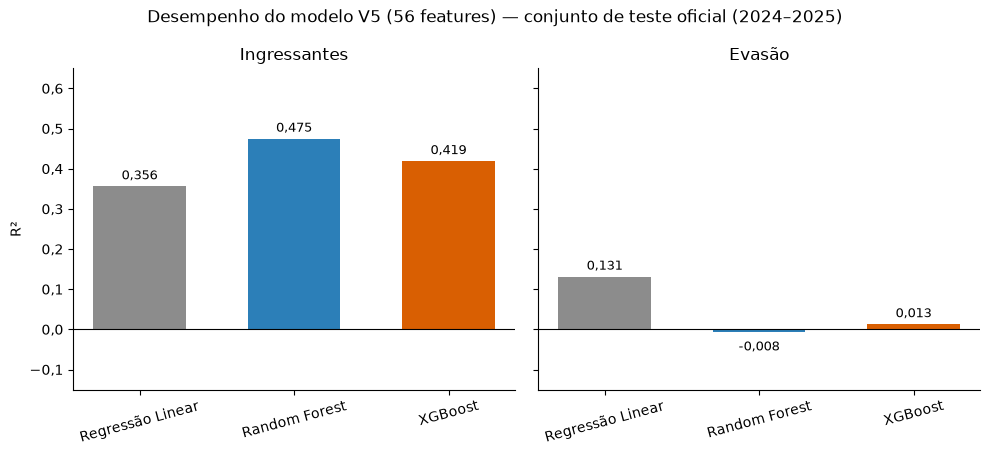

In [6]:
CORES = {'Regressão Linear': '#8c8c8c', 'Random Forest': '#2c7fb8', 'XGBoost': '#d95f02'}
ALVOS = {'ingressantes': 'Ingressantes', 'evasao': 'Evasão'}

res_v5 = []
for alvo, nome_alvo in ALVOS.items():
    for nome, m in modelos().items():
        a_te, p, _, _ = ajustar_prever(m, TR, TE, ORDEM_TABELA, alvo)
        res_v5.append({'Alvo': nome_alvo, 'Modelo': nome, **metricas(a_te[alvo], p)})
res_v5 = pd.DataFrame(res_v5)
display(res_v5.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, (nome_alvo, g) in zip(axes, res_v5.groupby('Alvo', sort=False)):
    barras = ax.bar(g['Modelo'], g['R²'], color=[CORES[m] for m in g['Modelo']], width=0.6)
    ax.axhline(0, color='black', lw=0.8)
    for b, v in zip(barras, g['R²']):
        ax.annotate(f'{v:.3f}', (b.get_x() + b.get_width() / 2, v), xytext=(0, 5 if v >= 0 else -13),
                    textcoords='offset points', ha='center', fontsize=9)
    ax.set_title(nome_alvo)
    ax.tick_params(axis='x', rotation=15)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('R²'); axes[0].set_ylim(-0.15, 0.65)
fig.suptitle('Desempenho do modelo V5 (56 features) — conjunto de teste oficial (2024–2025)')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_r2_v5.png', dpi=200, facecolor='white'); plt.show()

## 4. Análise descritiva da evasão — TCC, Seção 5.2

Taxa de evasão = evasão / matrículas ativas no mesmo ano (definição usada em todo o trabalho). Esta seção usa
todas as ofertas (não só as 113 da modelagem).

In [7]:
por_ano = df.groupby('ano')[['ingressantes', 'evasao', 'matriculas_ativas']].sum(min_count=1)
por_ano['taxa_evasao_%'] = por_ano.evasao / por_ano.matriculas_ativas * 100
print('Evasão por ano'); display(por_ano.round(1))

periodo = df.ano.apply(lambda a: '1. Pré-pandemia (2016-2019)' if a <= 2019 else ('2. Pandemia (2020-2021)' if a <= 2021 else '3. Pós-pandemia (2022-2025)'))
fases = df.groupby(periodo)[['ingressantes', 'evasao', 'matriculas_ativas']].sum(min_count=1)
fases['taxa_evasao_%'] = fases.evasao / fases.matriculas_ativas * 100
fases['ingressantes_por_ano'] = fases.ingressantes / df.groupby(periodo).ano.nunique()
print('Fases associadas à pandemia'); display(fases.round(2))

por_mod = df.groupby('mod_curso')[['evasao', 'matriculas_ativas']].sum(min_count=1)
por_mod['taxa_evasao_%'] = por_mod.evasao / por_mod.matriculas_ativas * 100
print('Evasão por modalidade do curso'); display(por_mod.round(1))

por_curso = df.groupby('curso')[['evasao', 'matriculas_ativas']].sum(min_count=1)
por_curso = por_curso[por_curso.matriculas_ativas >= 50]
por_curso['taxa_evasao_%'] = por_curso.evasao / por_curso.matriculas_ativas * 100
print('Cursos com maior e menor taxa de evasão (>= 50 matrículas ativas acumuladas)')
display(por_curso.sort_values('taxa_evasao_%', ascending=False).head(10).round(1))
display(por_curso.sort_values('taxa_evasao_%').head(10).round(1))

of = df.groupby('oferta_id')[['ingressantes', 'evasao', 'matriculas_ativas']].sum(min_count=1)
a = of.dropna(subset=['ingressantes', 'evasao'])
t = of.dropna().assign(taxa=lambda d: d.evasao / d.matriculas_ativas)
print(f'Escala: r(ingressantes, evasão) = {stats.pearsonr(a.ingressantes, a.evasao)[0]:.2f} ({len(a)} ofertas)')
print(f'Risco:  r(ingressantes, taxa de evasão) = {stats.pearsonr(t.ingressantes, t.taxa)[0]:.2f} (Pearson) / '
      f'{stats.spearmanr(t.ingressantes, t.taxa)[0]:.2f} (Spearman) ({len(t)} ofertas)')

Evasão por ano


,ingressantes,evasao,matriculas_ativas,taxa_evasao_%
ano,,,,
2016,6619.0,4036.0,14436.0,28.0
2017,6349.0,3426.0,15539.0,22.0
2018,5759.0,3756.0,16968.0,22.1
2019,6063.0,3874.0,18506.0,20.9
2020,4525.0,2181.0,17751.0,12.3
2021,5622.0,2223.0,18941.0,11.7
2022,4701.0,5198.0,18477.0,28.1
2023,5182.0,5386.0,18428.0,29.2
2024,5178.0,5554.0,18529.0,30.0


Fases associadas à pandemia


,ingressantes,evasao,matriculas_ativas,taxa_evasao_%,ingressantes_por_ano
ano,,,,,
1. Pré-pandemia (2016-2019),24790.0,15092.0,65449.0,23.06,6197.50
2. Pandemia (2020-2021),10147.0,4404.0,36692.0,12.00,5073.50
3. Pós-pandemia (2022-2025),19929.0,19809.0,73455.0,26.97,4982.25


Evasão por modalidade do curso


,evasao,matriculas_ativas,taxa_evasao_%
mod_curso,,,
Bacharelado,10166.0,59524.0,17.1
Licenciatura,15263.0,70390.0,21.7
Tecnologia,13876.0,45682.0,30.4


Cursos com maior e menor taxa de evasão (>= 50 matrículas ativas acumuladas)


,evasao,matriculas_ativas,taxa_evasao_%
curso,,,
Manutenção Industrial,59.0,83.0,71.1
Irrigação e Drenagem,583.0,1432.0,40.7
Estradas,843.0,2147.0,39.3
Saneamento Ambiental,1383.0,3687.0,37.5
"Educação Profissional, Científica e Tecnológica (EPCT)",79.0,220.0,35.9
Automação Industrial,586.0,1714.0,34.2
Telemática,1018.0,3007.0,33.9
Mecatrônica Industrial,2175.0,6800.0,32.0
Redes de Computadores,725.0,2296.0,31.6


,evasao,matriculas_ativas,taxa_evasao_%
curso,,,
Engenharia de Produção,9.0,332.0,2.7
Graduação em Educação Física - ABI,33.0,420.0,7.9
Pedagogia,59.0,610.0,9.7
Nutrição,189.0,1950.0,9.7
Engenharia Civil,743.0,5937.0,12.5
Engenharia Mecânica,212.0,1667.0,12.7
Letras,207.0,1574.0,13.2
Engenharia de Computação,625.0,4301.0,14.5
Análise e Desenvolvimento de Sistemas,162.0,1107.0,14.6


Escala: r(ingressantes, evasão) = 0.89 (133 ofertas)
Risco:  r(ingressantes, taxa de evasão) = 0.13 (Pearson) / 0.19 (Spearman) (131 ofertas)


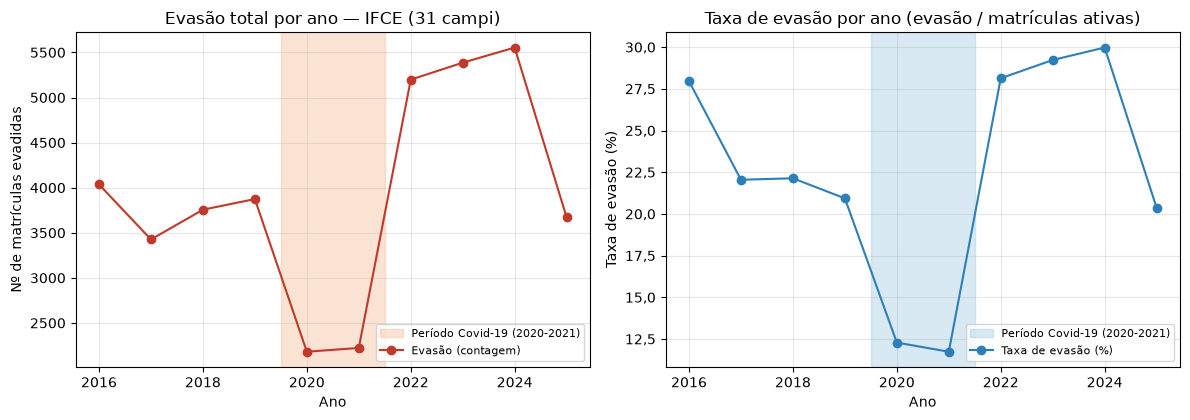

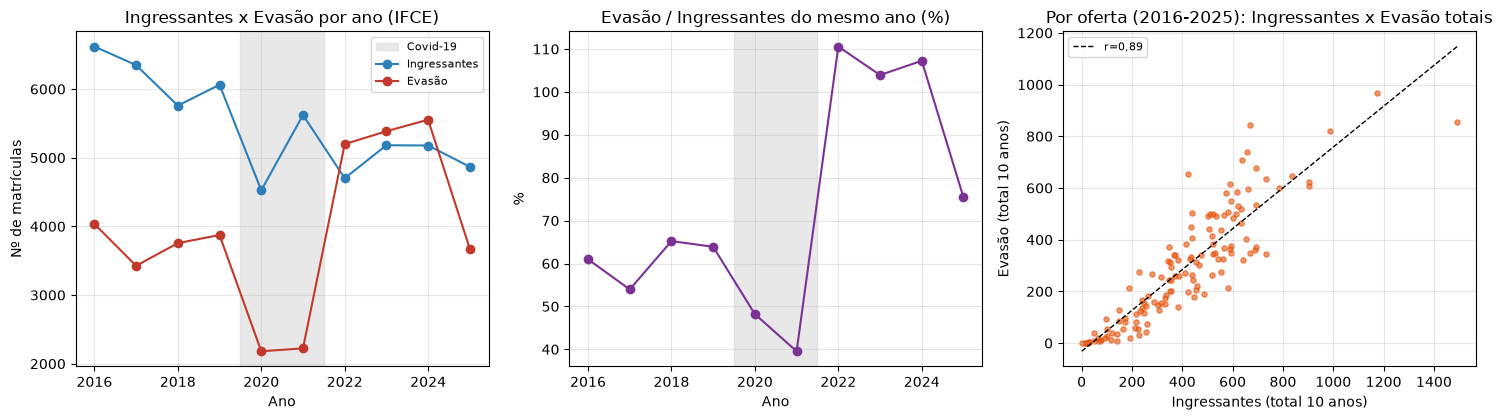

In [8]:
# Figura: evasão e taxa de evasão por ano
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax1.axvspan(2019.5, 2021.5, color='#f4b183', alpha=0.35, label='Período Covid-19 (2020-2021)')
ax1.plot(por_ano.index, por_ano.evasao, 'o-', color='#c0392b', label='Evasão (contagem)')
ax1.set_title('Evasão total por ano — IFCE (31 campi)'); ax1.set_xlabel('Ano'); ax1.set_ylabel('Nº de matrículas evadidas')
ax1.legend(fontsize=8, loc='lower right')
ax2.axvspan(2019.5, 2021.5, color='#9ecae1', alpha=0.4, label='Período Covid-19 (2020-2021)')
ax2.plot(por_ano.index, por_ano['taxa_evasao_%'], 'o-', color='#2c7fb8', label='Taxa de evasão (%)')
ax2.set_title('Taxa de evasão por ano (evasão / matrículas ativas)'); ax2.set_xlabel('Ano'); ax2.set_ylabel('Taxa de evasão (%)')
ax2.legend(fontsize=8, loc='lower right')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_evasao_covid.png', dpi=200, facecolor='white'); plt.show()

# Figura: ingressantes x evasão
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].axvspan(2019.5, 2021.5, color='#d9d9d9', alpha=0.6, label='Covid-19')
axes[0].plot(por_ano.index, por_ano.ingressantes, 'o-', color='#2c7fb8', label='Ingressantes')
axes[0].plot(por_ano.index, por_ano.evasao, 'o-', color='#c0392b', label='Evasão')
axes[0].set_title('Ingressantes x Evasão por ano (IFCE)'); axes[0].set_xlabel('Ano'); axes[0].set_ylabel('Nº de matrículas'); axes[0].legend(fontsize=8)
razao = por_ano.evasao / por_ano.ingressantes * 100
axes[1].axvspan(2019.5, 2021.5, color='#d9d9d9', alpha=0.6)
axes[1].plot(por_ano.index, razao, 'o-', color='#7b3294')
axes[1].set_title('Evasão / Ingressantes do mesmo ano (%)'); axes[1].set_xlabel('Ano'); axes[1].set_ylabel('%')
r_esc = stats.pearsonr(a.ingressantes, a.evasao)[0]
axes[2].scatter(a.ingressantes, a.evasao, s=14, alpha=0.6, color='#e6550d')
lim = max(a.ingressantes.max(), a.evasao.max())
coef = np.polyfit(a.ingressantes, a.evasao, 1); xs = np.linspace(0, a.ingressantes.max(), 50)
axes[2].plot(xs, np.polyval(coef, xs), 'k--', lw=1, label=f'r={r_esc:.2f}')
axes[2].set_title('Por oferta (2016-2025): Ingressantes x Evasão totais'); axes[2].set_xlabel('Ingressantes (total 10 anos)'); axes[2].set_ylabel('Evasão (total 10 anos)'); axes[2].legend(fontsize=8)
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_evasao_ingressantes.png', dpi=200, facecolor='white'); plt.show()

### 4.1 Testes estatísticos da análise descritiva (revisão)

A **taxa operacional de evasão** de um grupo $G$ (oferta, modalidade, período) é
$\text{TE}_G = \sum_{(o,t)\in G} E_{o,t} \,/\, \sum_{(o,t)\in G} M_{o,t}$, em que $E$ é "Matrícula (evadida)" e $M$ é
"Matrícula (em curso)" no mesmo ano. As comparações abaixo são feitas no **nível de oferta** (uma taxa acumulada por oferta),
o que evita tratar os anos de uma mesma oferta como observações independentes. São reportadas a taxa ponderada
(soma/soma), a mediana e a média simples por oferta, testes não paramétricos e tamanhos de efeito.

In [9]:
from itertools import combinations
rng_est = np.random.default_rng(42)

d0 = df.dropna(subset=['evasao', 'matriculas_ativas'])
print(f'Oferta-ano com evasão e matrículas ativas: {len(d0)} | casos com evasão > matrículas ativas: {(d0.evasao > d0.matriculas_ativas).sum()}')

ofx = df.groupby(['oferta_id', 'mod_curso'])[['evasao', 'matriculas_ativas', 'ingressantes']].sum(min_count=1).reset_index()
ofx = ofx.dropna(subset=['evasao', 'matriculas_ativas']); ofx = ofx[ofx.matriculas_ativas > 0]
ofx['taxa'] = ofx.evasao / ofx.matriculas_ativas

def cliff(x, y):
    U = stats.mannwhitneyu(x, y, alternative='two-sided')[0]
    return 2 * U / (len(x) * len(y)) - 1

for minimo in (0, 50):
    o = ofx[ofx.matriculas_ativas >= minimo]
    tab = o.groupby('mod_curso').agg(ofertas=('taxa', 'size'), evasao=('evasao', 'sum'), ativas=('matriculas_ativas', 'sum'),
                                     mediana=('taxa', 'median'), q1=('taxa', lambda s: s.quantile(.25)),
                                     q3=('taxa', lambda s: s.quantile(.75)), media_simples=('taxa', 'mean'))
    tab['taxa_ponderada'] = tab.evasao / tab.ativas
    print(f'\nModalidade, ofertas com >= {minimo} matrículas ativas acumuladas'); display(tab.round(3))
    grupos = [g.taxa.values for _, g in o.groupby('mod_curso')]
    H, p = stats.kruskal(*grupos); eps2 = (H - len(grupos) + 1) / (len(o) - len(grupos))
    print(f'Kruskal-Wallis: H = {H:.2f}, p = {p:.2g}, epsilon² = {eps2:.3f}')
    pares = [(a, b) for a, b in combinations(sorted(o.mod_curso.unique()), 2)]
    pv = [stats.mannwhitneyu(o[o.mod_curso == a].taxa, o[o.mod_curso == b].taxa, alternative='two-sided')[1] for a, b in pares]
    ordem = np.argsort(pv); adj = np.empty(len(pv)); acum = 0
    for r_, i in enumerate(ordem):
        acum = max(acum, min(1, pv[i] * (len(pv) - r_))); adj[i] = acum
    for (a, b), pp, pa in zip(pares, pv, adj):
        print(f'  {a} x {b}: p = {pp:.2g}, p (Holm) = {pa:.2g}, delta de Cliff = {cliff(o[o.mod_curso == a].taxa, o[o.mod_curso == b].taxa):+.2f}')

fase = df.ano.apply(lambda a: '1. Pré (2016-19)' if a <= 2019 else ('2. Pandemia (2020-21)' if a <= 2021 else '3. Pós (2022-25)'))
mf = df.assign(fase=fase).groupby(['mod_curso', 'fase'])[['evasao', 'matriculas_ativas']].sum(min_count=1)
print('\nTaxa operacional de evasão (%) por modalidade e fase'); display((mf.evasao / mf.matriculas_ativas * 100).unstack().round(1))

fo = df.assign(fase=fase).groupby(['oferta_id', 'fase'])[['evasao', 'matriculas_ativas']].sum(min_count=1)
fo = fo[fo.matriculas_ativas > 0]; w = (fo.evasao / fo.matriculas_ativas).unstack().dropna()
print(f'\nFases no nível de oferta ({len(w)} ofertas com dados nas três fases); medianas:', w.median().round(3).to_dict())
for a, b in [('1. Pré (2016-19)', '2. Pandemia (2020-21)'), ('2. Pandemia (2020-21)', '3. Pós (2022-25)'), ('1. Pré (2016-19)', '3. Pós (2022-25)')]:
    dif = w[b] - w[a]
    print(f'  {a} -> {b}: mediana da diferença = {dif.median() * 100:+.1f} p.p.; ofertas com aumento = {(dif > 0).mean() * 100:.0f}%; '
          f'Wilcoxon p = {stats.wilcoxon(w[a], w[b])[1]:.2g}')

def ic_spearman(x, y, B=2000):
    x, y = np.asarray(x), np.asarray(y); bs = []
    for _ in range(B):
        i = rng_est.integers(0, len(x), len(x)); bs.append(stats.spearmanr(x[i], y[i])[0])
    return np.percentile(bs, [2.5, 97.5])

print('\nPorte da oferta (ingressantes acumulados) x taxa operacional de evasão')
tt0 = ofx.dropna(subset=['ingressantes'])
for minimo in (0, 50):
    tt = tt0[tt0.matriculas_ativas >= minimo]
    r, p = stats.pearsonr(tt.ingressantes, tt.taxa); z, se = np.arctanh(r), 1 / np.sqrt(len(tt) - 3)
    rs, ps_ = stats.spearmanr(tt.ingressantes, tt.taxa); lo, hi = ic_spearman(tt.ingressantes, tt.taxa)
    print(f'  >= {minimo} ativas ({len(tt)} ofertas): Pearson r = {r:.2f} [IC95% {np.tanh(z - 1.96 * se):.2f}; {np.tanh(z + 1.96 * se):.2f}], p = {p:.3f} | '
          f'Spearman rho = {rs:.2f} [IC95% {lo:.2f}; {hi:.2f}], p = {ps_:.3f}')
    for mod, g in tt.groupby('mod_curso'):
        rr, pp = stats.spearmanr(g.ingressantes, g.taxa); print(f'      {mod}: {len(g)} ofertas, rho = {rr:.2f}, p = {pp:.3f}')

Oferta-ano com evasão e matrículas ativas: 1084 | casos com evasão > matrículas ativas: 11

Modalidade, ofertas com >= 0 matrículas ativas acumuladas


,ofertas,evasao,ativas,mediana,q1,q3,media_simples,taxa_ponderada
mod_curso,,,,,,,,
Bacharelado,38,10164.0,59524.0,0.156,0.129,0.199,0.159,0.171
Licenciatura,54,15263.0,70390.0,0.220,0.171,0.269,0.232,0.217
Tecnologia,44,13875.0,45681.0,0.298,0.234,0.352,0.309,0.304


Kruskal-Wallis: H = 38.87, p = 3.6e-09, epsilon² = 0.277
  Bacharelado x Licenciatura: p = 1.2e-05, p (Holm) = 2.4e-05, delta de Cliff = -0.54
  Bacharelado x Tecnologia: p = 4.2e-08, p (Holm) = 1.3e-07, delta de Cliff = -0.71
  Licenciatura x Tecnologia: p = 0.00065, p (Holm) = 0.00065, delta de Cliff = -0.40

Modalidade, ofertas com >= 50 matrículas ativas acumuladas


,ofertas,evasao,ativas,mediana,q1,q3,media_simples,taxa_ponderada
mod_curso,,,,,,,,
Bacharelado,35,10157.0,59441.0,0.161,0.137,0.203,0.165,0.171
Licenciatura,54,15263.0,70390.0,0.220,0.171,0.269,0.232,0.217
Tecnologia,40,13858.0,45623.0,0.295,0.234,0.342,0.288,0.304


Kruskal-Wallis: H = 34.35, p = 3.5e-08, epsilon² = 0.257
  Bacharelado x Licenciatura: p = 7.2e-05, p (Holm) = 0.00014, delta de Cliff = -0.50
  Bacharelado x Tecnologia: p = 1.6e-07, p (Holm) = 4.8e-07, delta de Cliff = -0.71
  Licenciatura x Tecnologia: p = 0.0011, p (Holm) = 0.0011, delta de Cliff = -0.40

Taxa operacional de evasão (%) por modalidade e fase


fase,1. Pré (2016-19),2. Pandemia (2020-21),3. Pós (2022-25)
mod_curso,,,
Bacharelado,17.7,11.0,19.3
Licenciatura,21.6,11.3,26.9
Tecnologia,30.2,14.5,40.4



Fases no nível de oferta (105 ofertas com dados nas três fases); medianas: {'1. Pré (2016-19)': 0.218, '2. Pandemia (2020-21)': 0.115, '3. Pós (2022-25)': 0.3}
  1. Pré (2016-19) -> 2. Pandemia (2020-21): mediana da diferença = -9.9 p.p.; ofertas com aumento = 12%; Wilcoxon p = 1.1e-15
  2. Pandemia (2020-21) -> 3. Pós (2022-25): mediana da diferença = +17.9 p.p.; ofertas com aumento = 98%; Wilcoxon p = 8.2e-19
  1. Pré (2016-19) -> 3. Pós (2022-25): mediana da diferença = +7.6 p.p.; ofertas com aumento = 89%; Wilcoxon p = 5.9e-15

Porte da oferta (ingressantes acumulados) x taxa operacional de evasão


  >= 0 ativas (131 ofertas): Pearson r = 0.13 [IC95% -0.04; 0.29], p = 0.145 | Spearman rho = 0.19 [IC95% 0.01; 0.36], p = 0.032
      Bacharelado: 38 ofertas, rho = 0.37, p = 0.023
      Licenciatura: 53 ofertas, rho = -0.10, p = 0.488
      Tecnologia: 40 ofertas, rho = 0.44, p = 0.005


  >= 50 ativas (127 ofertas): Pearson r = 0.05 [IC95% -0.12; 0.23], p = 0.552 | Spearman rho = 0.11 [IC95% -0.08; 0.29], p = 0.211
      Bacharelado: 35 ofertas, rho = 0.22, p = 0.199
      Licenciatura: 53 ofertas, rho = -0.10, p = 0.488
      Tecnologia: 39 ofertas, rho = 0.39, p = 0.014


## 5. Análise descritiva da ocupação de vagas — TCC, Seção 5.3

Ocupação = ingressantes / vagas ofertadas, por oferta e ano. Os anos de 2017 e 2020 têm inconsistências
sistemáticas na própria fonte de vagas (conferidas nos Anuários Estatísticos) e são excluídos das análises,
assim como observações com ocupação fora do intervalo de 10% a 150%.

In [10]:
ANOS_INCONSISTENTES = (2017, 2020)
obs = df.dropna(subset=['ingressantes', 'vagas_ofertadas']).copy()
obs = obs[obs.vagas_ofertadas > 0]
obs['ocup'] = obs.ingressantes / obs.vagas_ofertadas
print(f'{len(obs)} observações oferta-ano | {obs.oferta_id.nunique()} ofertas')
g = obs.groupby('ano')
display(pd.DataFrame({'ingressantes': g.ingressantes.sum(), 'vagas': g.vagas_ofertadas.sum(),
                      'ocupação mediana': g.ocup.median(), '% ofertas > 100%': g.ocup.apply(lambda s: (s > 1).mean() * 100)}).round(3))

val = obs[~obs.ano.isin(ANOS_INCONSISTENTES)]
fora = (val.ocup < 0.10) | (val.ocup > 1.50)
print(f'Observações fora de [10%, 150%] (excluídos 2017/2020): {fora.sum()}')
val = val[~fora].copy()
print(f'Base final: {len(val)} observações de {val.oferta_id.nunique()} ofertas')

per = val.ano.apply(lambda a: '2016, 2018, 2019' if a <= 2019 else ('2021' if a == 2021 else '2022-2025'))
display(val.groupby(per).ocup.agg(n='size', mediana='median', pct_abaixo_80=lambda s: (s < .8).mean() * 100).round(3))
tab7 = val.groupby('mod_curso').ocup.agg(n='size', mediana='median', pct_abaixo_80=lambda s: (s < .8).mean() * 100)
tab7['taxa_evasao_%'] = por_mod['taxa_evasao_%']
print('Ocupação por modalidade do curso'); display(tab7.round(3))

ofertas = val.groupby(['oferta_id', 'campus', 'curso', 'mod_curso']).agg(n=('ocup', 'size'), ocup_med=('ocup', 'median')).reset_index()
ofertas = ofertas.merge((of.evasao / of.matriculas_ativas).rename('taxa_ev'), left_on='oferta_id', right_index=True)
of4 = ofertas[(ofertas.n >= 4) & ofertas.taxa_ev.notna()].copy()
rho, p = stats.spearmanr(of4.ocup_med, of4.taxa_ev)
print(f'Ofertas com >= 4 obs: {len(of4)} | Spearman(ocupação mediana, taxa de evasão) = {rho:.3f} (p = {p:.2g})')
of4['quartil'] = pd.qcut(of4.ocup_med, 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
display(of4.groupby('quartil').agg(n=('oferta_id', 'size'), ocup_min=('ocup_med', 'min'), ocup_max=('ocup_med', 'max'),
                                   taxa_evasao_mediana=('taxa_ev', 'median')).round(3))
for mod, gg in of4.groupby('mod_curso'):
    r, pp = stats.spearmanr(gg.ocup_med, gg.taxa_ev)
    print(f'  {mod}: n={len(gg)}, rho={r:.3f}, p={pp:.3f}')
abaixo = of4[of4.ocup_med < .8]
print(f'Ofertas com ocupação mediana < 80%: {len(abaixo)} ({len(abaixo) / len(of4) * 100:.1f}%) —',
      abaixo.mod_curso.value_counts().to_dict(), '| do campus Fortaleza:', (abaixo.campus == 'Fortaleza').sum())
display(of4.sort_values('ocup_med').head(5)[['campus', 'curso', 'mod_curso', 'n', 'ocup_med', 'taxa_ev']].round(3))

982 observações oferta-ano | 128 ofertas


,ingressantes,vagas,ocupação mediana,% ofertas > 100%
ano,,,,
2016,6580.0,6481.0,1.000,46.835
2017,5240.0,19241.0,0.304,4.819
2018,5693.0,6031.0,0.987,29.348
2019,6005.0,6714.0,0.955,15.842
2020,4418.0,3336.0,1.071,62.500
2021,4928.0,5909.0,0.911,7.292
2022,4625.0,5855.0,0.814,23.585
2023,4968.0,5678.0,0.923,32.407
2024,4677.0,5182.0,0.950,39.091


Observações fora de [10%, 150%] (excluídos 2017/2020): 25
Base final: 778 observações de 127 ofertas


,n,mediana,pct_abaixo_80
ano,,,
"2016, 2018, 2019",266,0.972,11.654
2021,96,0.911,31.250
2022-2025,416,0.886,38.942


Ocupação por modalidade do curso


,n,mediana,pct_abaixo_80,taxa_evasao_%
mod_curso,,,,
Bacharelado,220,1.000,10.909,17.079
Licenciatura,331,0.889,37.160,21.683
Tecnologia,227,0.897,33.480,30.375


Ofertas com >= 4 obs: 107 | Spearman(ocupação mediana, taxa de evasão) = -0.340 (p = 0.00034)


,n,ocup_min,ocup_max,taxa_evasao_mediana
quartil,,,,
Q1,27,0.317,0.750,0.258
Q2,27,0.762,0.914,0.236
Q3,32,0.933,1.000,0.211
Q4,21,1.006,1.150,0.161


  Bacharelado: n=29, rho=-0.576, p=0.001
  Licenciatura: n=48, rho=-0.142, p=0.334
  Tecnologia: n=30, rho=-0.040, p=0.834
Ofertas com ocupação mediana < 80%: 33 (30.8%) — {'Licenciatura': 21, 'Tecnologia': 11, 'Bacharelado': 1} | do campus Fortaleza: 0


,campus,curso,mod_curso,n,ocup_med,taxa_ev
71,Jaguaribe,Ciências Biológicas,Licenciatura,8,0.317,0.219
95,Maranguape,Matemática,Licenciatura,4,0.343,0.411
62,Horizonte,Física,Licenciatura,4,0.357,0.297
14,Boa Viagem,Química,Licenciatura,7,0.382,0.153
24,Canindé,Música,Licenciatura,4,0.517,0.172


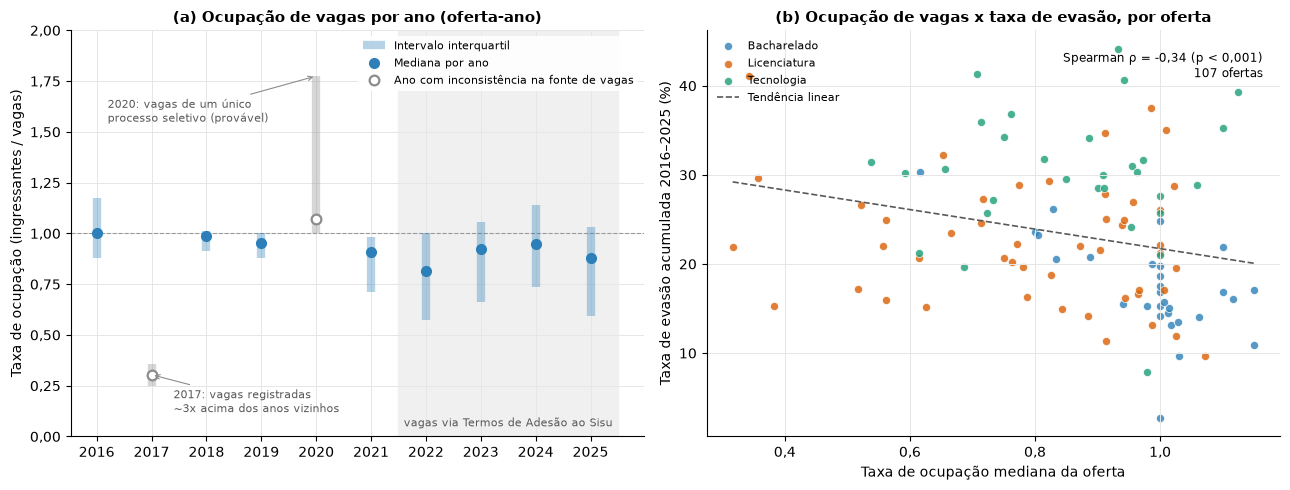

In [11]:
# Figura: ocupação por ano e ocupação x evasão
CORES_MOD = {'Bacharelado': '#2c7fb8', 'Licenciatura': '#d95f02', 'Tecnologia': '#1b9e77'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
anos = sorted(obs.ano.unique()); gq = obs.groupby('ano').ocup
med, q1, q3 = gq.median(), gq.quantile(.25), gq.quantile(.75)
ok = [a for a in anos if a not in ANOS_INCONSISTENTES]; ruins = list(ANOS_INCONSISTENTES)
ax1.axhline(1.0, color='#999999', lw=0.8, ls='--')
ax1.vlines(ok, q1[ok], q3[ok], color='#2c7fb8', lw=6, alpha=0.35, label='Intervalo interquartil')
ax1.plot(ok, med[ok], 'o', color='#2c7fb8', ms=7, label='Mediana por ano')
ax1.vlines(ruins, q1[ruins], q3[ruins], color='#8c8c8c', lw=6, alpha=0.35)
ax1.plot(ruins, med[ruins], 'o', mfc='white', mec='#8c8c8c', mew=1.6, ms=7, label='Ano com inconsistência na fonte de vagas')
ax1.annotate('2017: vagas registradas\n~3x acima dos anos vizinhos', xy=(2017, med[2017]), xytext=(2017.4, 0.12),
             fontsize=8, color='#595959', arrowprops=dict(arrowstyle='->', color='#8c8c8c', lw=0.8))
ax1.annotate('2020: vagas de um único\nprocesso seletivo (provável)', xy=(2020, q3[2020]), xytext=(2016.2, 1.55),
             fontsize=8, color='#595959', arrowprops=dict(arrowstyle='->', color='#8c8c8c', lw=0.8))
ax1.axvspan(2021.5, 2025.5, color='#f0f0f0', zorder=0)
ax1.text(2023.5, 0.05, 'vagas via Termos de Adesão ao Sisu', ha='center', fontsize=7.8, color='#595959')
ax1.set_xticks(anos); ax1.set_ylim(0, 2.0); ax1.set_ylabel('Taxa de ocupação (ingressantes / vagas)')
ax1.set_title('(a) Ocupação de vagas por ano (oferta-ano)', fontsize=10.5, fontweight='bold')
ax1.legend(fontsize=8, loc='upper right', frameon=True, facecolor='white', edgecolor='none', framealpha=0.9)
for mod, gg in of4.groupby('mod_curso'):
    ax2.scatter(gg.ocup_med, gg.taxa_ev * 100, s=34, color=CORES_MOD[mod], alpha=0.8, edgecolor='white', lw=0.6, label=mod)
coef = np.polyfit(of4.ocup_med, of4.taxa_ev * 100, 1); xs = np.linspace(of4.ocup_med.min(), of4.ocup_med.max(), 50)
ax2.plot(xs, np.polyval(coef, xs), color='#595959', lw=1.2, ls='--', label='Tendência linear')
ax2.text(0.97, 0.95, f'Spearman ρ = {rho:.2f} (p < 0,001)\n{len(of4)} ofertas'.replace('.', ','), transform=ax2.transAxes,
         ha='right', va='top', fontsize=8.5)
ax2.set_xlabel('Taxa de ocupação mediana da oferta'); ax2.set_ylabel('Taxa de evasão acumulada 2016–2025 (%)')
ax2.set_title('(b) Ocupação de vagas x taxa de evasão, por oferta', fontsize=10.5, fontweight='bold')
ax2.legend(fontsize=8, loc='upper left', frameon=False)
for ax in (ax1, ax2):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.grid(color='#e6e6e6', lw=0.7, zorder=0)
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_ocupacao_vagas.png', dpi=150, facecolor='white'); plt.show()

### 5.0 Auditoria da série de vagas e sensibilidade à fonte (revisão)

Fonte de cada ano, cobertura (ofertas com ingressantes que têm vagas registradas), totais e indicadores de consistência.
Em seguida, a associação entre ocupação e evasão é recalculada separadamente para os anos dos Anuários e para os anos do Sisu.

In [12]:
fonte_vagas = {a: f'Anuário Estatístico {a + 1} (ano-base {a})' for a in range(2016, 2022)}
fonte_vagas.update({a: f'Termo de Adesão ao Sisu {a}' for a in range(2022, 2026)})
com_ing = df[df.ingressantes > 0]
aud = []
for a in range(2016, 2026):
    oi = set(com_ing[com_ing.ano == a].oferta_id); vv = obs[obs.ano == a]
    aud.append({'Ano': a, 'Fonte': fonte_vagas[a], 'Ofertas c/ ingressantes': len(oi), 'Com vagas': len(oi & set(vv.oferta_id)),
                'Cobertura (%)': len(oi & set(vv.oferta_id)) / len(oi) * 100, 'Vagas': vv.vagas_ofertadas.sum(),
                'Ingressantes': vv.ingressantes.sum(), 'Ocupação mediana': vv.ocup.median(),
                '% > 100%': (vv.ocup > 1).mean() * 100, '% < 80%': (vv.ocup < .8).mean() * 100,
                'Fora de 10-150%': ((vv.ocup < .1) | (vv.ocup > 1.5)).sum(),
                'Uso': 'excluído' if a in ANOS_INCONSISTENTES else 'usado'})
aud = pd.DataFrame(aud); display(aud.round(1))
n_exc = obs.ano.isin(ANOS_INCONSISTENTES).sum()
n_out = (~obs.ano.isin(ANOS_INCONSISTENTES) & ((obs.ocup < .1) | (obs.ocup > 1.5))).sum()
print(f'Observações oferta-ano com vagas: {len(obs)} | em 2017/2020: {n_exc} ({n_exc / len(obs) * 100:.1f}%) | '
      f'fora de 10-150%: {n_out} ({n_out / len(obs) * 100:.1f}%) | usadas: {len(obs) - n_exc - n_out}')

taxa_of = (df.groupby('oferta_id').evasao.sum(min_count=1) / df.groupby('oferta_id').matriculas_ativas.sum(min_count=1)).rename('taxa_ev')
rng_vag = np.random.default_rng(42)
def ocup_evasao(anos, rotulo, min_obs):
    v = obs[obs.ano.isin(anos) & (obs.ocup >= .1) & (obs.ocup <= 1.5)]
    o = v.groupby(['oferta_id', 'mod_curso']).agg(n=('ocup', 'size'), ocup_med=('ocup', 'median')).reset_index()
    o = o.merge(taxa_of, left_on='oferta_id', right_index=True); o = o[(o.n >= min_obs) & o.taxa_ev.notna()]
    rho_, p_ = stats.spearmanr(o.ocup_med, o.taxa_ev); bs = []
    for _ in range(2000):
        i = rng_vag.integers(0, len(o), len(o)); bs.append(stats.spearmanr(o.ocup_med.values[i], o.taxa_ev.values[i])[0])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f'{rotulo}: {len(o)} ofertas | rho = {rho_:.2f} [IC95% {lo:.2f}; {hi:.2f}], p = {p_:.2g} | obs. com ocupação < 80%: {(v.ocup < .8).mean() * 100:.1f}%')
ocup_evasao([2016, 2018, 2019, 2021, 2022, 2023, 2024, 2025], 'Principal (todas as fontes, excl. 2017/2020)', 4)
ocup_evasao([2016, 2018, 2019, 2021], 'Só Anuários (2016, 2018, 2019, 2021)', 4)
ocup_evasao([2022, 2023, 2024, 2025], 'Só Termos do Sisu (2022-2025)', 4)

,Ano,Fonte,Ofertas c/ ingressantes,Com vagas,Cobertura (%),Vagas,Ingressantes,Ocupação mediana,% > 100%,% < 80%,Fora de 10-150%,Uso
0,2016,Anuário Estatístico 2017 (ano-base 2016),81,79,97.5,6481.0,6580.0,1.0,46.8,12.7,3,usado
1,2017,Anuário Estatístico 2018 (ano-base 2017),87,83,95.4,19241.0,5240.0,0.3,4.8,89.2,1,excluído
2,2018,Anuário Estatístico 2019 (ano-base 2018),93,92,98.9,6031.0,5693.0,1.0,29.3,7.6,2,usado
3,2019,Anuário Estatístico 2020 (ano-base 2019),103,101,98.1,6714.0,6005.0,1.0,15.8,13.9,1,usado
4,2020,Anuário Estatístico 2021 (ano-base 2020),99,96,97.0,3336.0,4418.0,1.1,62.5,6.2,26,excluído
5,2021,Anuário Estatístico 2022 (ano-base 2021),105,96,91.4,5909.0,4928.0,0.9,7.3,31.2,0,usado
6,2022,Termo de Adesão ao Sisu 2022,109,106,97.2,5855.0,4625.0,0.8,23.6,46.2,2,usado
7,2023,Termo de Adesão ao Sisu 2023,112,108,96.4,5678.0,4968.0,0.9,32.4,33.3,6,usado
8,2024,Termo de Adesão ao Sisu 2024,117,110,94.0,5182.0,4677.0,1.0,39.1,30.9,8,usado
9,2025,Termo de Adesão ao Sisu 2025,116,111,95.7,5712.0,4605.0,0.9,27.9,39.6,3,usado


Observações oferta-ano com vagas: 982 | em 2017/2020: 179 (18.2%) | fora de 10-150%: 25 (2.5%) | usadas: 778


Principal (todas as fontes, excl. 2017/2020): 107 ofertas | rho = -0.34 [IC95% -0.51; -0.16], p = 0.00034 | obs. com ocupação < 80%: 28.7%


Só Anuários (2016, 2018, 2019, 2021): 68 ofertas | rho = -0.43 [IC95% -0.61; -0.21], p = 0.0003 | obs. com ocupação < 80%: 16.9%


Só Termos do Sisu (2022-2025): 79 ofertas | rho = -0.28 [IC95% -0.47; -0.05], p = 0.014 | obs. com ocupação < 80%: 38.9%


### 5.1 Análise de sensibilidade: vagas de 2017 e 2020 corrigidas

A ablação de *features* (seção 10) é reexecutada substituindo as vagas de 2017 e 2020 de cada oferta pela média dos
anos vizinhos da mesma oferta.

In [13]:
def ablacao(dados):
    b, _ = construir_base(dados)
    tr, te, dum = preparar(b[b.ano <= ANO_CORTE].copy(), b[b.ano > ANO_CORTE].copy())
    blocos = {'A (4)': BLOCO_A, 'B (7)': BLOCO_B, 'C (15)': BLOCO_C, 'D (56, V5)': BLOCO_C + ['ano', 'curso_enc'] + dum}
    linhas = []
    for alvo, nome_alvo in ALVOS.items():
        for bloco, cols in blocos.items():
            for nome, m in modelos().items():
                a_te, p, _, _ = ajustar_prever(m, tr, te, cols, alvo)
                linhas.append({'Alvo': nome_alvo, 'Modelo': nome, 'Bloco': bloco, 'R²': r2_score(a_te[alvo], p)})
    return pd.DataFrame(linhas)

df_corr = df.sort_values(['oferta_id', 'ano']).copy()
for oid, g in df_corr.groupby('oferta_id'):
    s = g.set_index('ano')['vagas_ofertadas']
    for a_ in ANOS_INCONSISTENTES:
        if a_ in s.index and pd.notna(s.get(a_)):
            viz = [x for x in (s.get(a_ - 1), s.get(a_ + 1)) if pd.notna(x)]
            df_corr.loc[(df_corr.oferta_id == oid) & (df_corr.ano == a_), 'vagas_ofertadas'] = np.mean(viz) if viz else np.nan

abl_orig = ablacao(df)
abl_corr = ablacao(df_corr)
sens = abl_orig.merge(abl_corr, on=['Alvo', 'Modelo', 'Bloco'], suffixes=(' vagas originais', ' vagas corrigidas'))
sens['Δ'] = sens['R² vagas corrigidas'] - sens['R² vagas originais']
display(sens.round(3))

,Alvo,Modelo,Bloco,R² vagas originais,R² vagas corrigidas,Δ
0,Ingressantes,Regressão Linear,A (4),0.574,0.574,0.000
1,Ingressantes,Random Forest,A (4),0.419,0.419,0.000
2,Ingressantes,XGBoost,A (4),0.386,0.386,0.000
3,Ingressantes,Regressão Linear,B (7),0.572,0.495,-0.076
4,Ingressantes,Random Forest,B (7),0.468,0.438,-0.029
5,Ingressantes,XGBoost,B (7),0.393,0.358,-0.035
6,Ingressantes,Regressão Linear,C (15),0.444,0.453,0.008
7,Ingressantes,Random Forest,C (15),0.514,0.506,-0.007
8,Ingressantes,XGBoost,C (15),0.448,0.365,-0.083
9,Ingressantes,Regressão Linear,"D (56, V5)",0.356,0.349,-0.008


## 6. Projeção multianual de Ingressantes (2026–2029) — TCC, Seção 5.4

1. Ranking das ofertas pelo erro percentual médio do *Random Forest* no teste oficial (porte ≥ 15 ingressantes/ano).
2. O modelo é retreinado com todo o histórico 2016–2025 e projeta 2026–2029 de forma **recursiva**: a previsão de
   um ano alimenta as defasagens do ano seguinte; evasão, matrículas, concluintes e vagas ficam congeladas no nível de 2025.
3. A faixa mostra a dispersão de 300 trajetórias recursivas, uma por árvore da floresta (percentis 2,5–97,5);
   não é um intervalo de confiança ou de previsão formal.
2027–2029 são projeções exploratórias; o erro esperado em cada horizonte é medido retrospectivamente na seção 6.3.

In [14]:
# 6.1 Erro por oferta no teste oficial (ordem de colunas do notebook original da V5)
rf_teste = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
a_te, p, _, _ = ajustar_prever(rf_teste, TR, TE, ORDEM_NOTEBOOK, 'ingressantes')
print(f'R² do Random Forest (Ingressantes) nesta ordem de colunas: {r2_score(a_te.ingressantes, p):.4f}')
res = teste.loc[a_te.index, ['campus', 'curso', 'mod_curso', 'oferta_id', 'ano']].copy()
res['real'] = a_te.ingressantes.values; res['previsto'] = p
res['erro_pct'] = (res.previsto - res.real).abs() / res.real.replace(0, np.nan) * 100
por_oferta = res.groupby(['oferta_id', 'campus', 'curso', 'mod_curso']).agg(real_medio=('real', 'mean'), erro_pct=('erro_pct', 'mean')).reset_index()
ranking = por_oferta[por_oferta.real_medio >= 15].sort_values('erro_pct')
print(f'{len(por_oferta)} ofertas no teste; {len(ranking)} com porte >= 15/ano')
display(ranking.head(10).round(1))
print('Ofertas do campus Aracati no teste:')
display(por_oferta[por_oferta.campus == 'Aracati'].round(1))

R² do Random Forest (Ingressantes) nesta ordem de colunas: 0.4771
99 ofertas no teste; 97 com porte >= 15/ano


,oferta_id,campus,curso,mod_curso,real_medio,erro_pct
73,Maracanaú | Engenharia Mecânica | Bacharelado ...,Maracanaú,Engenharia Mecânica,Bacharelado,31.0,1.7
36,Fortaleza | Engenharia de Computação | Bachare...,Fortaleza,Engenharia de Computação,Bacharelado,81.0,2.1
20,Caucaia | Matemática | Licenciatura | Presencial,Caucaia,Matemática,Licenciatura,31.5,3.3
74,Maracanaú | Engenharia de Controle e Automação...,Maracanaú,Engenharia de Controle e Automação,Bacharelado,30.5,3.5
34,Fortaleza | Artes Visuais | Licenciatura | Pre...,Fortaleza,Artes Visuais,Licenciatura,66.5,4.0
11,Camocim | Letras - Português e Inglês | Licenc...,Camocim,Letras - Português e Inglês,Licenciatura,44.0,5.1
69,Limoeiro do Norte | Nutrição | Bacharelado | P...,Limoeiro do Norte,Nutrição,Bacharelado,44.0,5.5
38,Fortaleza | Engenharia de Telecomunicações | B...,Fortaleza,Engenharia de Telecomunicações,Bacharelado,93.0,5.9
33,Crato | Zootecnia | Bacharelado | Presencial,Crato,Zootecnia,Bacharelado,55.5,6.5
72,Maracanaú | Engenharia Ambiental e Sanitária |...,Maracanaú,Engenharia Ambiental e Sanitária,Bacharelado,80.0,6.7


Ofertas do campus Aracati no teste:


,oferta_id,campus,curso,mod_curso,real_medio,erro_pct
3,Aracati | Ciência da Computação | Bacharelado ...,Aracati,Ciência da Computação,Bacharelado,45.5,45.9
4,Aracati | Hotelaria | Tecnologia | Presencial,Aracati,Hotelaria,Tecnologia,21.0,51.0
5,Aracati | Química | Licenciatura | Presencial,Aracati,Química,Licenciatura,39.0,16.1


In [15]:
# 6.2 Projeção recursiva 2026-2029
HORIZONTE = [2026, 2027, 2028, 2029]
base_full = base.dropna(subset=['ingressantes']).copy()
mapa_f, mg_f = fit_target_encoding(base, 'curso', 'ingressantes')
full = apply_target_encoding(base_full, 'curso', mapa_f, mg_f, 'curso_enc')
full_oh = pd.get_dummies(full, columns=CATEGORICAS, prefix=CATEGORICAS)
dum_full = [c for c in full_oh.columns if c.startswith(PREFIXOS)]
COLS_FULL = NUMERICAS_V5 + dum_full
rf_full = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(full_oh[COLS_FULL].fillna(0).astype(float), full_oh.ingressantes)
EXOG = ['evasao_lag1', 'evasao_ma3', 'matriculas_ativas_lag1', 'matriculas_ativas_ma3', 'taxa_evasao_hist',
        'concluintes_lag1', 'concluintes_ma3', 'taxa_conclusao_hist', 'vagas_ofertadas_lag1', 'vagas_ofertadas_ma3', 'taxa_ocupacao_hist']

def linha_features(serie, exog, ano, meta):
    v = [serie[a] for a in sorted(serie)]
    lin = {'ano': ano, 'curso_enc': meta['enc'], 'ingressantes_lag1': v[-1],
           'ingressantes_lag2': v[-2] if len(v) >= 2 else np.nan,
           'ingressantes_ma3': np.mean(v[-3:]) if len(v) >= 3 else np.nan,
           'ingressantes_cresc_pct': (v[-1] / v[-2] - 1) if len(v) >= 2 and v[-2] not in (0, np.nan) and not np.isnan(v[-2]) else np.nan}
    lin.update({k: exog[k] for k in EXOG})
    lin.update({c: meta['dummies'].get(c, 0) for c in dum_full})
    return pd.DataFrame([lin])[COLS_FULL].fillna(0).astype(float)

def projetar(oferta_id):
    g = df[df.oferta_id == oferta_id].sort_values('ano').copy()
    ult = g.iloc[-1]
    nova = {c: np.nan for c in g.columns}
    nova.update({k: ult[k] for k in ['campus', 'curso', 'mod_curso', 'mod_ensino', 'cod_cine', 'area_cine', 'oferta_id']}); nova['ano'] = int(g.ano.max()) + 1
    ext = add_features(pd.concat([g, pd.DataFrame([nova])], ignore_index=True))
    exog = ext[ext.ano == nova['ano']].iloc[0][EXOG].to_dict()
    meta = {'enc': mapa_f.get(ult.curso, mg_f),
            'dummies': {f'campus_{ult.campus}': 1, f'mod_curso_{ult.mod_curso}': 1, f'mod_ensino_{ult.mod_ensino}': 1, f'area_cine_{ult.area_cine}': 1}}
    real = {a: v for a, v in zip(g.ano, g.ingressantes) if pd.notna(v)}
    serie, oficial = dict(real), {}
    for ano in HORIZONTE:
        oficial[ano] = rf_full.predict(linha_features(serie, exog, ano, meta))[0]; serie[ano] = oficial[ano]
    traj = np.zeros((len(rf_full.estimators_), len(HORIZONTE)))
    for i, arv in enumerate(rf_full.estimators_):
        s = dict(real)
        for j, ano in enumerate(HORIZONTE):
            traj[i, j] = arv.predict(linha_features(s, exog, ano, meta).values)[0]; s[ano] = traj[i, j]
    return {'real': real, 'oficial': oficial, 'traj': traj}

ofertas_aracati = sorted(df[df.campus == 'Aracati'].oferta_id.unique())
ofertas_melhores = ranking.head(3).oferta_id.tolist()
projecoes = {o: projetar(o) for o in ofertas_aracati + ofertas_melhores}
tab = []
for o, r in projecoes.items():
    for j, ano in enumerate(HORIZONTE):
        tab.append({'oferta': o, 'ano': ano, 'previsto': r['oficial'][ano],
                    'faixa_2,5%': max(0, np.percentile(r['traj'][:, j], 2.5)), 'faixa_97,5%': np.percentile(r['traj'][:, j], 97.5),
                    'dispersao_relativa_%': r['traj'][:, j].std() / r['oficial'][ano] * 100})
display(pd.DataFrame(tab).round(1))

,oferta,ano,previsto,"faixa_2,5%","faixa_97,5%",dispersao_relativa_%
0,Aracati | Ciência da Computação | Bacharelado ...,2026,51.1,20.4,77.0,27.4
1,Aracati | Ciência da Computação | Bacharelado ...,2027,51.1,20.4,77.0,30.9
2,Aracati | Ciência da Computação | Bacharelado ...,2028,51.3,19.0,76.5,29.7
3,Aracati | Ciência da Computação | Bacharelado ...,2029,50.9,21.5,72.0,28.7
4,Aracati | Engenharia de Aquicultura | Bacharel...,2026,23.6,10.0,41.0,39.1
5,Aracati | Engenharia de Aquicultura | Bacharel...,2027,20.1,10.0,41.0,40.2
6,Aracati | Engenharia de Aquicultura | Bacharel...,2028,20.2,10.0,41.0,44.1
7,Aracati | Engenharia de Aquicultura | Bacharel...,2029,21.1,10.0,44.1,45.3
8,Aracati | Hotelaria | Tecnologia | Presencial,2026,20.0,4.0,37.5,42.9
9,Aracati | Hotelaria | Tecnologia | Presencial,2027,20.1,4.0,39.6,42.1


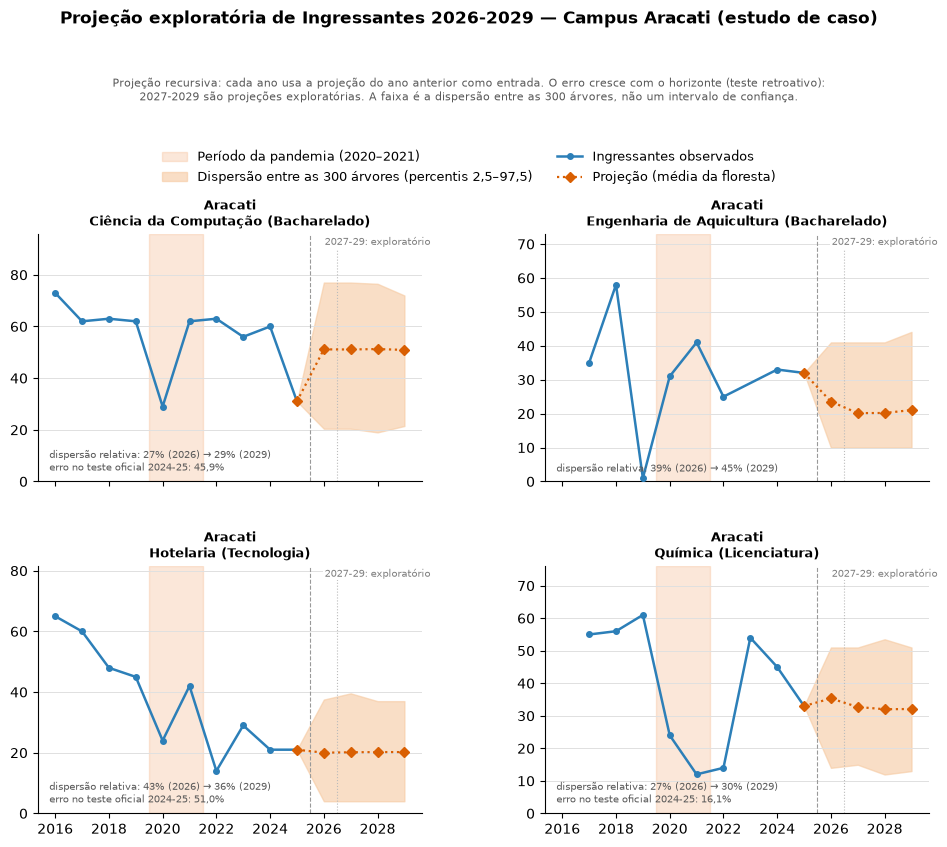

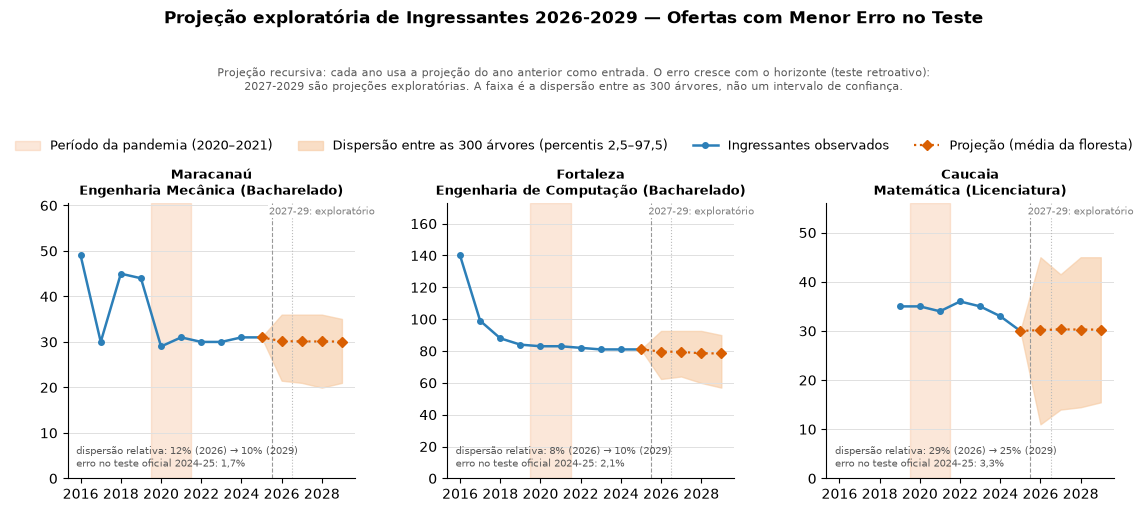

In [16]:
def grafico_projecao(lista, nrows, ncols, figsize, titulo, arquivo, top, legend_ncol):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=True)
    axes = np.atleast_1d(axes).flatten()
    for ax, o in zip(axes, lista):
        r = projecoes[o]; anos_r = sorted(r['real']); vals = [r['real'][a] for a in anos_r]
        lo = np.clip(np.percentile(r['traj'], 2.5, axis=0), 0, None); hi = np.percentile(r['traj'], 97.5, axis=0)
        ax.axvspan(2019.5, 2021.5, color='#f4b183', alpha=0.3, zorder=0, label='Período da pandemia (2020–2021)')
        ax.fill_between([anos_r[-1]] + HORIZONTE, [vals[-1]] + list(lo), [vals[-1]] + list(hi), color='#f6c9a0', alpha=0.6,
                        zorder=1, label='Dispersão entre as 300 árvores (percentis 2,5–97,5)')
        ax.plot(anos_r, vals, marker='o', ms=4, color='#2c7fb8', lw=1.8, label='Ingressantes observados', zorder=3)
        ax.plot([anos_r[-1]] + HORIZONTE, [vals[-1]] + [r['oficial'][a] for a in HORIZONTE], marker='D', ms=5.5, ls=':',
                color='#d95f02', lw=1.6, label='Projeção (média da floresta)', zorder=4)
        campus, curso, mod = o.split(' | ')[:3]
        ax.set_title(f'{campus}\n{curso} ({mod})', fontsize=9.6, fontweight='bold')
        ax.set_ylim(bottom=0); ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
        ax.grid(axis='y', color='#e0e0e0', lw=0.7); ax.axvline(2025.5, color='#999999', lw=0.8, ls='--')
        ax.axvline(2026.5, color='#bbbbbb', lw=0.8, ls=':')
        ytop = ax.get_ylim()[1]; ax.set_ylim(0, ytop * 1.2)
        ax.text(2028, ytop * 1.185, '2027-29: exploratório', ha='center', va='top', fontsize=7, color='#808080',
                bbox=dict(facecolor='white', edgecolor='none', pad=1.0), zorder=5)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
        cv0 = r['traj'][:, 0].std() / r['oficial'][2026] * 100; cv3 = r['traj'][:, -1].std() / r['oficial'][2029] * 100
        linha = f'dispersão relativa: {cv0:.0f}% (2026) → {cv3:.0f}% (2029)'
        e = por_oferta.set_index('oferta_id').erro_pct.get(o)
        if e is not None and pd.notna(e): linha += f'\nerro no teste oficial 2024-25: {e:.1f}%'
        ax.annotate(linha, xy=(0.03, 0.03), xycoords='axes fraction', fontsize=7.5, color='#595959', va='bottom')
    fig.subplots_adjust(top=top, hspace=0.34, wspace=0.32)
    livre = 1 - top
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='center', ncol=legend_ncol, bbox_to_anchor=(0.5, top + livre * 0.28), frameon=False, fontsize=9)
    fig.text(0.5, top + livre * 0.60, 'Projeção recursiva: cada ano usa a projeção do ano anterior como entrada. O erro cresce com o horizonte (teste retroativo):\n'
             '2027-2029 são projeções exploratórias. A faixa é a dispersão entre as 300 árvores, não um intervalo de confiança.',
             ha='center', va='center', fontsize=7.7, color='#595959')
    fig.text(0.5, top + livre * 0.90, titulo, ha='center', va='center', fontsize=12.5, fontweight='bold')
    aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/{arquivo}', dpi=170, facecolor='white'); plt.show()

grafico_projecao(ofertas_aracati, 2, 2, (11.5, 9.2), 'Projeção exploratória de Ingressantes 2026-2029 — Campus Aracati (estudo de caso)',
                 'fig_previsao_aracati.png', 0.74, 2)
grafico_projecao(ofertas_melhores, 1, 3, (13.5, 5.4), 'Projeção exploratória de Ingressantes 2026-2029 — Ofertas com Menor Erro no Teste',
                 'fig_previsao_melhores_ofertas.png', 0.62, 4)

### 6.3 Teste retroativo de horizonte (1 a 4 anos) (revisão)

Para medir o erro da projeção recursiva além de um ano, o mesmo procedimento da seção 6.2 é aplicado ao passado:
para cada ano de origem $T_0 \in \{2019, \dots, 2024\}$, o modelo é treinado só com dados até $T_0$, projeta
$T_0+1, \dots, T_0+4$ de forma recursiva (variáveis exógenas congeladas em $T_0$) e é comparado com o valor real.
As referências ingênuas são a persistência (repetir o último valor observado) e a média dos três últimos anos.

MAE por origem e horizonte


Método            Random Forest  XGBoost  Persistência  Média móvel 3 anos
Origem Horizonte                                                          
2019   1                  18.79    18.64         21.33               19.59
       2                  15.17    15.55         16.46               15.34
       3                  17.76    17.61         19.85               18.27
       4                  17.71    17.86         18.67               17.90
2020   1                  14.37    15.57         15.26               12.16
       2                  13.52    14.67         14.42               15.28
       3                  14.85    15.99         15.38               14.48
       4                  13.79    14.57         15.69               17.62
2021   1                  11.79    11.96         13.88               12.98
       2                  11.59    11.36         12.06               11.87
       3                  12.86    13.31         15.55               14.86
       4                  13.44    13.48         16.23               15.13
2022   1                   9.68    10.62         10.78                8.98
       2                  12.89    14.82         14.51               12.25
       3                  13.58    15.25         14.60               13.08
2023   1                  10.45    11.26          9.22               10.97
       2                  11.58    11.30         10.15               11.99
2024   1                   9.07     8.93          8.49                9.59

Média entre as origens disponíveis (h=1: 6 origens; h=2: 5; h=3: 4; h=4: 3)


MAE                             R²                     
Horizonte                1       2       3       4      1      2      3      4
Método                                                                        
Random Forest       12.358  12.952  14.762  14.982  0.313  0.263  0.143  0.022
XGBoost             12.829  13.542  15.540  15.303  0.258  0.173  0.023 -0.045
Persistência        13.160  13.520  16.346  16.863  0.167  0.122 -0.142 -0.373
Média móvel 3 anos  12.377  13.345  15.173  16.883  0.295  0.236  0.024 -0.282

MAE do Random Forest / MAE da persistência, por horizonte


,mean,min,max
Horizonte,,,
1,0.96,0.85,1.13
2,0.97,0.89,1.14
3,0.90,0.83,0.97
4,0.89,0.83,0.95


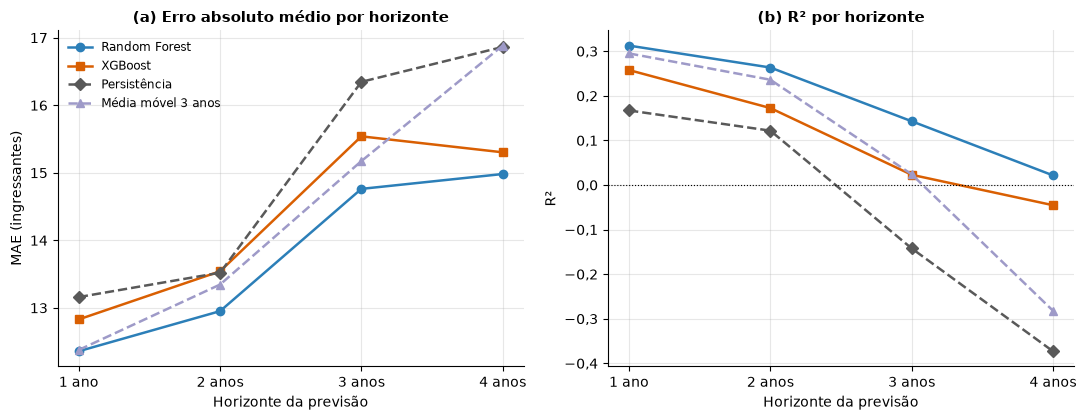

In [17]:
ING_F = ['ingressantes_lag1', 'ingressantes_lag2', 'ingressantes_ma3', 'ingressantes_cresc_pct']
def feats_ing(v):
    l1 = v[-1]; l2 = v[-2] if len(v) >= 2 else np.nan
    return [l1, l2, np.mean(v[-3:]) if len(v) >= 3 else np.nan, (l1 / l2 - 1) if (len(v) >= 2 and not np.isnan(l2) and l2 != 0) else np.nan]

real_ing = df.set_index(['oferta_id', 'ano']).ingressantes
hz = []
for T0 in range(2019, 2025):
    fut = []
    for oid in base.oferta_id.unique():
        g = df[(df.oferta_id == oid) & (df.ano <= T0)].sort_values('ano'); s = g.set_index('ano').ingressantes
        if s.dropna().size < 3 or pd.isna(s.get(T0)):
            continue
        ult = g.iloc[-1]; nova = {c: np.nan for c in g.columns}
        nova.update({k: ult[k] for k in ['campus', 'curso', 'mod_curso', 'mod_ensino', 'cod_cine', 'area_cine', 'oferta_id']}); nova['ano'] = T0 + 1
        lin = add_features(pd.concat([g, pd.DataFrame([nova])], ignore_index=True)).query('ano == @T0 + 1').iloc[0].to_dict()
        lin['serie'] = list(s.dropna().values); fut.append(lin)
    fut = pd.DataFrame(fut)
    tr_h, te_h, dum_h = preparar(base[base.ano <= T0].copy(), fut.drop(columns=['serie']))
    cols_h = NUMERICAS_V5 + dum_h; a_h = tr_h.dropna(subset=['ingressantes'])
    ms = {n: modelos()[n].fit(a_h[cols_h].fillna(0).astype(float), a_h.ingressantes) for n in ['Random Forest', 'XGBoost']}
    series = {n: [list(s) for s in fut.serie] for n in ms}; prev = {n: [] for n in ms}
    for h in range(1, 5):
        Xh = te_h.copy(); Xh['ano'] = T0 + h
        for n, m in ms.items():
            Xh[ING_F] = np.array([feats_ing(s) for s in series[n]])
            p = m.predict(Xh[cols_h].fillna(0).astype(float)); prev[n].append(p)
            for s, v in zip(series[n], p): s.append(v)
    for h in range(1, 5):
        if T0 + h > 2025: continue
        y = np.array([real_ing.get((o, T0 + h), np.nan) for o in fut.oferta_id]); ok = ~np.isnan(y)
        cand = {**{n: prev[n][h - 1] for n in ms}, 'Persistência': np.array([s[-1] for s in fut.serie]),
                'Média móvel 3 anos': np.array([np.mean(s[-3:]) for s in fut.serie])}
        for n, p in cand.items():
            hz.append({'Origem': T0, 'Horizonte': h, 'Método': n, 'n': int(ok.sum()), **metricas(y[ok], p[ok])})
hz = pd.DataFrame(hz)
print('MAE por origem e horizonte'); display(hz.pivot_table(index=['Origem', 'Horizonte'], columns='Método', values='MAE', sort=False).round(2))
res_h = hz.groupby(['Método', 'Horizonte'], sort=False)[['MAE', 'R²']].mean().unstack()
print('Média entre as origens disponíveis (h=1: 6 origens; h=2: 5; h=3: 4; h=4: 3)'); display(res_h.round(3))
razao = hz.pivot_table(index=['Origem', 'Horizonte'], columns='Método', values='MAE')
razao = (razao['Random Forest'] / razao['Persistência']).groupby(level='Horizonte').agg(['mean', 'min', 'max'])
print('MAE do Random Forest / MAE da persistência, por horizonte'); display(razao.round(2))

CORES_H = {'Random Forest': '#2c7fb8', 'XGBoost': '#d95f02', 'Persistência': '#595959', 'Média móvel 3 anos': '#9e9ac8'}
ESTILO = {'Random Forest': 'o-', 'XGBoost': 's-', 'Persistência': 'D--', 'Média móvel 3 anos': '^--'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
for n in CORES_H:
    ax1.plot(range(1, 5), res_h.loc[n, 'MAE'].values, ESTILO[n], color=CORES_H[n], lw=1.8, label=n)
    ax2.plot(range(1, 5), res_h.loc[n, 'R²'].values, ESTILO[n], color=CORES_H[n], lw=1.8, label=n)
ax1.set_ylabel('MAE (ingressantes)'); ax2.set_ylabel('R²'); ax2.axhline(0, color='black', lw=0.8, ls=':')
for ax, t in [(ax1, '(a) Erro absoluto médio por horizonte'), (ax2, '(b) R² por horizonte')]:
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(['1 ano', '2 anos', '3 anos', '4 anos']); ax.set_xlabel('Horizonte da previsão')
    ax.set_title(t, fontsize=10.5, fontweight='bold'); ax.grid(alpha=0.3)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
ax1.legend(fontsize=8.5, frameon=False)
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_horizonte.png', dpi=200, facecolor='white'); plt.show()

## 7. Auditoria de integridade temporal — TCC, Seção 5.5

Verifica (i) que nenhuma das 113 ofertas modeladas tem ano ausente no meio da série (o `shift` desloca por posição
de linha) e (ii) a proporção de valores ausentes nas *features* de concluintes.

In [18]:
modeladas = hist[hist >= 4].index
anos_of = df[df.oferta_id.isin(modeladas)].groupby('oferta_id').ano.apply(lambda s: sorted(s.unique()))
gaps = anos_of.apply(lambda a: len(set(range(a[0], a[-1] + 1)) - set(a)) > 0)
print(f'Ofertas modeladas: {len(anos_of)} | com lacuna interna na série: {gaps.sum()} | com menos de 10 anos (início tardio): {(anos_of.apply(len) < 10).sum()}')
aus = base[['concluintes_lag1', 'concluintes_ma3', 'taxa_conclusao_hist']].isna()
print('Valores ausentes nas 633 linhas de modelagem:')
display(pd.DataFrame({'ausentes': aus.sum(), '%': aus.mean() * 100}).round(1))

Ofertas modeladas: 113 | com lacuna interna na série: 0 | com menos de 10 anos (início tardio): 33
Valores ausentes nas 633 linhas de modelagem:


,ausentes,%
concluintes_lag1,96,15.2
concluintes_ma3,179,28.3
taxa_conclusao_hist,90,14.2


### 7.1 Teste automático de vazamento por perturbação (revisão)

Para cada oferta modelada e cada ano $t$: (a) todos os indicadores brutos do próprio ano $t$ são alterados e verifica-se que
**nenhuma** *feature* do ano $t$ muda; (b) cada indicador de $t-1, \dots, t-4$ é alterado isoladamente para registrar de quais anos
cada *feature* depende. Por fim, verifica-se que o *target encoding* do curso não muda quando o alvo do conjunto de teste é alterado.

In [19]:
RAW = ['ingressantes', 'evasao', 'matriculas_ativas', 'concluintes', 'vagas_ofertadas']
FEATS = [c for c in NUMERICAS_V5 if c not in ('ano', 'curso_enc')]
depende = {f: set() for f in FEATS}; violacoes = testes = 0
for oid in base.oferta_id.unique():
    g = df[df.oferta_id == oid].sort_values('ano').reset_index(drop=True); f0 = add_features(g)
    for t in g.ano[3:]:
        g2 = g.copy(); g2.loc[g2.ano == t, RAW] = g2.loc[g2.ano == t, RAW] * 7 + 13
        if not np.allclose(f0.loc[f0.ano == t, FEATS].values, add_features(g2).loc[lambda d: d.ano == t, FEATS].values, equal_nan=True):
            violacoes += 1
        for k in (1, 2, 3, 4):
            for v in RAW:
                g3 = g.copy(); g3.loc[g3.ano == t - k, v] = g3.loc[g3.ano == t - k, v] * 7 + 13; f3 = add_features(g3)
                for f in FEATS:
                    if not np.allclose(f0.loc[f0.ano == t, f].values, f3.loc[f3.ano == t, f].values, equal_nan=True):
                        depende[f].add((v, k))
        testes += 1
print(f'{testes} pares oferta-ano testados | features do ano t alteradas ao perturbar o próprio ano t: {violacoes}')
display(pd.DataFrame([{'feature': f, 'depende de': ', '.join(sorted({v for v, _ in depende[f]})),
                       'anos': ', '.join(f't-{k}' for k in sorted({k for _, k in depende[f]}))} for f in FEATS]))
_, te_a, _ = preparar(treino.copy(), teste.copy()); te_mod = teste.copy(); te_mod['ingressantes'] *= 3
_, te_b, _ = preparar(treino.copy(), te_mod)
print('O target encoding do teste muda quando o alvo do teste é alterado?', not np.allclose(te_a.curso_enc, te_b.curso_enc))

686 pares oferta-ano testados | features do ano t alteradas ao perturbar o próprio ano t: 0


,feature,depende de,anos
0,ingressantes_lag1,ingressantes,t-1
1,ingressantes_lag2,ingressantes,t-2
2,ingressantes_ma3,ingressantes,"t-1, t-2, t-3"
3,ingressantes_cresc_pct,ingressantes,"t-1, t-2"
4,evasao_lag1,evasao,t-1
5,evasao_ma3,evasao,"t-1, t-2, t-3"
6,matriculas_ativas_lag1,matriculas_ativas,t-1
7,matriculas_ativas_ma3,matriculas_ativas,"t-1, t-2, t-3"
8,taxa_evasao_hist,"evasao, matriculas_ativas","t-1, t-2, t-3, t-4"
9,concluintes_lag1,concluintes,t-1


O target encoding do teste muda quando o alvo do teste é alterado? False


## 8. Validação temporal *walk-forward* — TCC, Seção 5.6

Janela expansiva: o treino sempre começa em 2016; o teste é um único ano (2021 a 2025). *Target encoding* e *one-hot*
são reajustados a cada *fold*, só com os dados de treino daquele *fold*. Esta seção calcula também o Bloco C (seção 11).

In [20]:
wf = []
for ano_teste in range(2021, 2026):
    tr, te, dum = preparar(base[base.ano <= ano_teste - 1].copy(), base[base.ano == ano_teste].copy())
    for bloco, cols in [('C', BLOCO_C), ('D', NUMERICAS_V5 + dum)]:
        for alvo, nome_alvo in ALVOS.items():
            for nome, m in modelos().items():
                a_te, p, _, _ = ajustar_prever(m, tr, te, cols, alvo)
                wf.append({'Bloco': bloco, 'Alvo': nome_alvo, 'Modelo': nome, 'Ano de teste': ano_teste,
                           'n treino': len(tr.dropna(subset=[alvo])), 'n teste': len(a_te), **metricas(a_te[alvo], p)})
wf = pd.DataFrame(wf)
wfD = wf[wf.Bloco == 'D']
print('R² por fold (modelo completo, Bloco D)')
display(wfD.pivot_table(index=['Alvo', 'Modelo'], columns='Ano de teste', values='R²', sort=False).round(3))

def resumo(d):
    g, ge = d.groupby(['Alvo', 'Modelo'], sort=False)['R²'], d[d['Ano de teste'] != 2021].groupby(['Alvo', 'Modelo'], sort=False)['R²']
    return pd.DataFrame({'R² médio': g.mean(), 'Desvio-padrão': g.std(), 'R² médio (excl. 2021)': ge.mean(), 'Desvio-padrão (excl. 2021)': ge.std()})
print('Médias e desvios-padrão entre os 5 folds')
display(resumo(wfD).round(3))

R² por fold (modelo completo, Bloco D)


Ano de teste                     2021   2022   2023   2024   2025
Alvo         Modelo                                              
Ingressantes Regressão Linear -13.919  0.332  0.390  0.340  0.506
             Random Forest      0.115  0.530  0.586  0.420  0.625
             XGBoost           -0.061  0.512  0.556  0.303  0.615
Evasão       Regressão Linear  -8.029 -1.435  0.158  0.320 -0.455
             Random Forest     -0.499 -1.058  0.279  0.175 -0.539
             XGBoost           -0.494 -0.999  0.295  0.073 -0.757

Médias e desvios-padrão entre os 5 folds


R² médio  Desvio-padrão  R² médio (excl. 2021)  Desvio-padrão (excl. 2021)
Alvo         Modelo                                                                                      
Ingressantes Regressão Linear    -2.470          6.400                  0.392                       0.080
             Random Forest        0.455          0.205                  0.540                       0.089
             XGBoost              0.385          0.276                  0.497                       0.136
Evasão       Regressão Linear    -1.888          3.501                 -0.353                       0.795
             Random Forest       -0.329          0.554                 -0.286                       0.630
             XGBoost             -0.376          0.547                 -0.347                       0.627

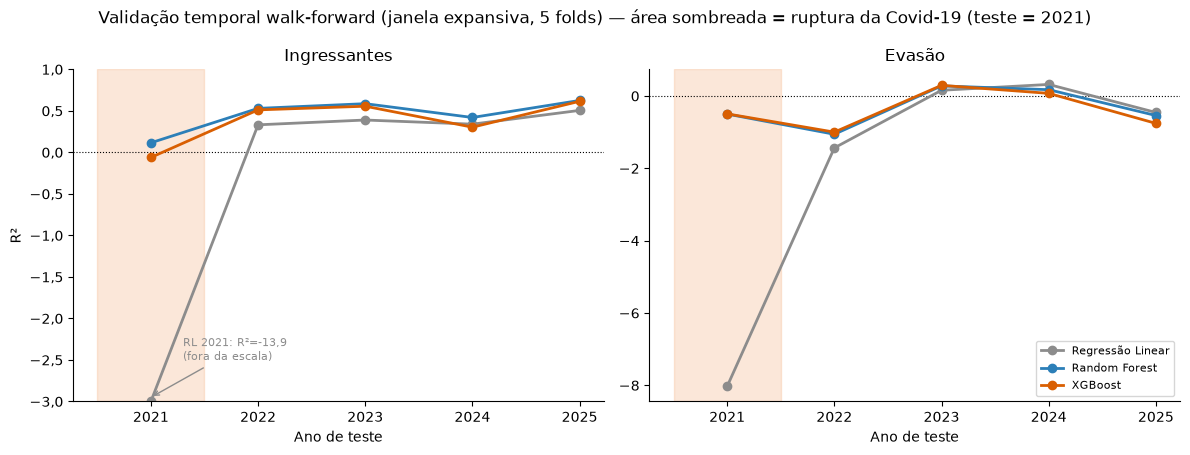

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, nome_alvo in zip(axes, ALVOS.values()):
    ax.axvspan(2020.5, 2021.5, color='#f4b183', alpha=0.3)
    ax.axhline(0, color='black', lw=0.8, ls=':')
    for nome in CORES:
        s = wfD[(wfD.Alvo == nome_alvo) & (wfD.Modelo == nome)]
        ax.plot(s['Ano de teste'], s['R²'].clip(lower=-3 if nome_alvo == 'Ingressantes' else None), 'o-', color=CORES[nome], lw=2, label=nome)
    ax.set_title(nome_alvo); ax.set_xlabel('Ano de teste'); ax.set_xticks(range(2021, 2026))
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
axes[0].set_ylim(-3, 1); axes[0].set_ylabel('R²')
rl = wfD[(wfD.Alvo == 'Ingressantes') & (wfD.Modelo == 'Regressão Linear') & (wfD['Ano de teste'] == 2021)]['R²'].iloc[0]
axes[0].annotate(f'RL 2021: R²={rl:.1f}\n(fora da escala)', xy=(2021, -2.95), xytext=(2021.3, -2.5), fontsize=8, color='#8c8c8c',
                 arrowprops=dict(arrowstyle='->', color='#8c8c8c', lw=1))
axes[1].legend(fontsize=8, loc='lower right')
fig.suptitle('Validação temporal walk-forward (janela expansiva, 5 folds) — área sombreada = ruptura da Covid-19 (teste = 2021)')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_walk_forward.png', dpi=200, facecolor='white'); plt.show()

### 8.1 Referências ingênuas (*baselines*) e tabela por janela (revisão)

Três previsões ingênuas, avaliadas exatamente nas mesmas linhas dos modelos: **persistência** (valor do ano anterior),
**média móvel de 3 anos** e **média histórica da oferta** (média de todos os anos anteriores). A tabela por janela registra
os anos de treino, o ano de teste e o número de linhas de cada *fold*.

Teste oficial 2024-2025: modelos x referências ingênuas


,Alvo,Método,n teste,RMSE,MAE,R²
0,Ingressantes,Regressão Linear,186,14.905,11.406,0.356
1,Ingressantes,Random Forest,186,13.463,10.456,0.475
2,Ingressantes,XGBoost,186,14.159,10.776,0.419
3,Ingressantes,Persistência (ano anterior),186,12.835,8.640,0.523
4,Ingressantes,Média móvel 3 anos,186,13.981,10.095,0.434
5,Ingressantes,Média histórica da oferta,186,19.984,15.387,-0.157
6,Evasão,Regressão Linear,193,23.328,17.879,0.131
7,Evasão,Random Forest,193,25.125,20.023,-0.008
8,Evasão,XGBoost,193,24.868,19.603,0.013
9,Evasão,Persistência (ano anterior),193,28.333,22.383,-0.281


Janelas do walk-forward


n treino  Ofertas no teste  n teste
Ano de teste Anos de treino Alvo                                             
2021         2016-2020      Ingressantes       158                86       86
                            Evasão             164                86       86
2022         2016-2021      Ingressantes       244                94       93
                            Evasão             250                94       94
2023         2016-2022      Ingressantes       337                96       90
                            Evasão             344                96       96
2024         2016-2023      Ingressantes       427                94       92
                            Evasão             440                94       94
2025         2016-2024      Ingressantes       519                99       94
                            Evasão             534                99       99

Ingressantes: R² por janela e médias


Ano de teste,2021,2022,2023,2024,2025,Média (excl. 2021),Média (5 folds),MAE médio (excl. 2021)
Método,,,,,,,,
Regressão Linear,-13.919,0.332,0.390,0.340,0.506,0.392,-2.470,11.399
Random Forest,0.115,0.530,0.586,0.420,0.625,0.540,0.455,10.130
XGBoost,-0.061,0.512,0.556,0.303,0.615,0.497,0.385,10.596
Persistência (ano anterior),-0.004,0.484,0.467,0.395,0.626,0.493,0.394,10.051
Média móvel 3 anos,0.371,0.516,0.605,0.275,0.562,0.489,0.466,10.377
Média histórica da oferta,0.066,0.245,0.256,-0.362,0.009,0.037,0.043,15.192


Evasão: R² por janela e médias


Ano de teste,2021,2022,2023,2024,2025,Média (excl. 2021),Média (5 folds),MAE médio (excl. 2021)
Método,,,,,,,,
Regressão Linear,-8.029,-1.435,0.158,0.320,-0.455,-0.353,-1.888,23.280
Random Forest,-0.499,-1.058,0.279,0.175,-0.539,-0.286,-0.329,22.424
XGBoost,-0.494,-0.999,0.295,0.073,-0.757,-0.347,-0.376,22.464
Persistência (ano anterior),-0.362,-0.990,-0.086,-0.056,-1.234,-0.592,-0.546,24.584
Média móvel 3 anos,-0.880,-0.329,-0.346,-0.102,-0.952,-0.432,-0.522,24.048
Média histórica da oferta,-1.453,-0.008,0.061,-0.153,-0.028,-0.032,-0.316,20.842


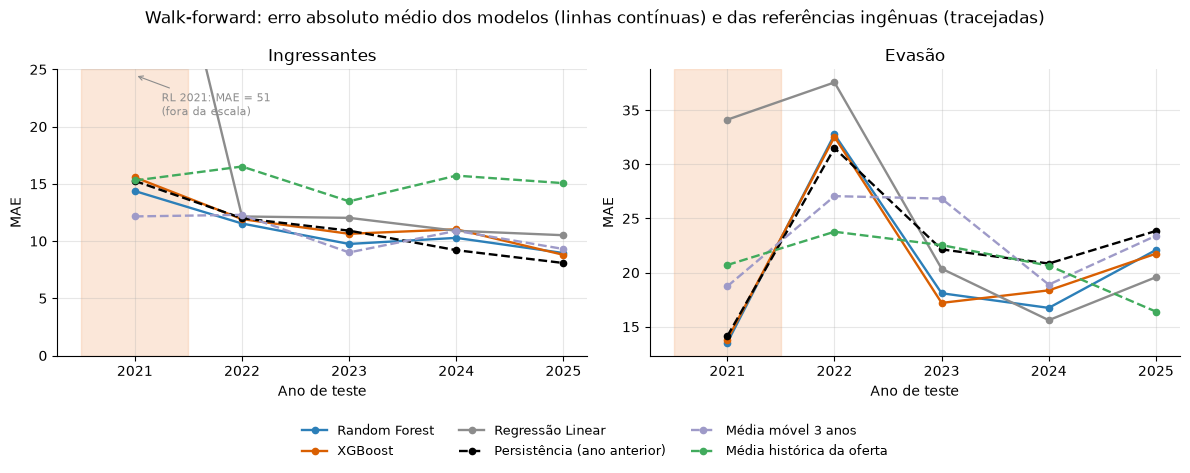

In [22]:
hist_mean = df.sort_values(['oferta_id', 'ano']).copy()
for alvo in ALVOS:
    hist_mean[f'{alvo}_hist_mean'] = hist_mean.groupby('oferta_id')[alvo].transform(lambda s: s.shift(1).expanding().mean())
base_b = base.merge(hist_mean[['oferta_id', 'ano', 'ingressantes_hist_mean', 'evasao_hist_mean']], on=['oferta_id', 'ano'], how='left')
BASELINES = {'Persistência (ano anterior)': '{}_lag1', 'Média móvel 3 anos': '{}_ma3', 'Média histórica da oferta': '{}_hist_mean'}

def avaliar(tr_rows, te_rows, cols_fn, rotulo):
    tr, te, dum = preparar(tr_rows.copy(), te_rows.copy()); linhas, prevs = [], []
    for alvo, nome_alvo in ALVOS.items():
        ref = te.dropna(subset=[alvo]); pl = ref[['oferta_id', 'ano', alvo]].rename(columns={alvo: 'real'}).assign(Alvo=nome_alvo, corte=rotulo)
        for nome, m in modelos().items():
            a_te, p, _, _ = ajustar_prever(m, tr, te, cols_fn(dum), alvo); pl[nome] = pd.Series(p, index=a_te.index)
            linhas.append({'Alvo': nome_alvo, 'Método': nome, 'n teste': len(a_te), **metricas(a_te[alvo], p)})
        for nome, padrao in BASELINES.items():
            prev = ref[padrao.format(alvo)]; ok = prev.notna(); pl[nome] = prev
            linhas.append({'Alvo': nome_alvo, 'Método': nome, 'n teste': int(ok.sum()), **metricas(ref.loc[ok, alvo], prev[ok])})
        prevs.append(pl)
    return pd.DataFrame(linhas), pd.concat(prevs)

of_b, prev_of = avaliar(base_b[base_b.ano <= ANO_CORTE], base_b[base_b.ano > ANO_CORTE], lambda dum: ORDEM_TABELA, 'oficial')
print('Teste oficial 2024-2025: modelos x referências ingênuas'); display(of_b.round(3))

wf_b, prev_wf = [], []
for ano_teste in range(2021, 2026):
    trr, ter = base_b[base_b.ano <= ano_teste - 1], base_b[base_b.ano == ano_teste]
    r, pl = avaliar(trr, ter, lambda dum: NUMERICAS_V5 + dum, f'wf{ano_teste}')
    r['Ano de teste'] = ano_teste; r['Anos de treino'] = f'2016-{ano_teste - 1}'
    r['n treino'] = r.Alvo.map({'Ingressantes': trr.ingressantes.notna().sum(), 'Evasão': trr.evasao.notna().sum()})
    r['Ofertas no teste'] = ter.oferta_id.nunique(); wf_b.append(r); prev_wf.append(pl)
wf_b = pd.concat(wf_b); prev_wf = pd.concat(prev_wf)
print('Janelas do walk-forward'); display(wf_b.groupby(['Ano de teste', 'Anos de treino', 'Alvo'], sort=False)[['n treino', 'Ofertas no teste', 'n teste']].max())
for nome_alvo in ALVOS.values():
    g = wf_b[wf_b.Alvo == nome_alvo]
    t = g.pivot_table(index='Método', columns='Ano de teste', values='R²', sort=False)
    t['Média (excl. 2021)'] = t[[2022, 2023, 2024, 2025]].mean(axis=1); t['Média (5 folds)'] = t[[2021, 2022, 2023, 2024, 2025]].mean(axis=1)
    m_ = g.pivot_table(index='Método', columns='Ano de teste', values='MAE', sort=False)
    t['MAE médio (excl. 2021)'] = m_[[2022, 2023, 2024, 2025]].mean(axis=1)
    print(f'{nome_alvo}: R² por janela e médias'); display(t.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
CORES_B = {'Random Forest': '#2c7fb8', 'XGBoost': '#d95f02', 'Regressão Linear': '#8c8c8c',
           'Persistência (ano anterior)': '#000000', 'Média móvel 3 anos': '#9e9ac8', 'Média histórica da oferta': '#41ab5d'}
for ax, nome_alvo in zip(axes, ALVOS.values()):
    g = wf_b[wf_b.Alvo == nome_alvo]
    for nome, cor in CORES_B.items():
        s = g[g.Método == nome]; ls = '--' if nome in BASELINES else '-'
        ax.plot(s['Ano de teste'], s['MAE'], marker='o', ls=ls, color=cor, lw=1.7, ms=4.5, label=nome)
    ax.axvspan(2020.5, 2021.5, color='#f4b183', alpha=0.3); ax.set_xticks(range(2021, 2026))
    ax.set_title(nome_alvo); ax.set_xlabel('Ano de teste'); ax.set_ylabel('MAE'); ax.grid(alpha=0.3)
    if nome_alvo == 'Ingressantes': ax.set_ylim(0, 25)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
axes[0].annotate('RL 2021: MAE = {:.0f}\n(fora da escala)'.format(wf_b[(wf_b.Alvo == 'Ingressantes') & (wf_b.Método == 'Regressão Linear') & (wf_b['Ano de teste'] == 2021)].MAE.iloc[0]),
                 xy=(2021, 24.5), xytext=(2021.25, 21), fontsize=8, color='#8c8c8c', arrowprops=dict(arrowstyle='->', color='#8c8c8c', lw=0.8))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Walk-forward: erro absoluto médio dos modelos (linhas contínuas) e das referências ingênuas (tracejadas)')
fig.tight_layout(rect=(0, 0.1, 1, 1)); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_baselines.png', dpi=200, facecolor='white'); plt.show()

### 8.2 Incerteza das comparações: *bootstrap* por oferta (revisão)

Diferença de MAE entre dois métodos com intervalo de confiança de 95% obtido por *bootstrap* por conglomerado: as ofertas são
reamostradas com reposição (2.000 réplicas), mantendo juntos todos os anos de uma mesma oferta. Intervalo que não contém zero indica
diferença distinguível do acaso; valor negativo favorece o primeiro método.

In [23]:
rng_b = np.random.default_rng(42)
def dif_mae(d, a, b, B=2000):
    d = d.dropna(subset=[a, b, 'real']); ofs = d.oferta_id.unique(); pos = {o: np.where(d.oferta_id.values == o)[0] for o in ofs}
    ea, eb = np.abs(d[a].values - d.real.values), np.abs(d[b].values - d.real.values); bs = []
    for _ in range(B):
        ii = np.concatenate([pos[o] for o in rng_b.choice(ofs, len(ofs), replace=True)]); bs.append(ea[ii].mean() - eb[ii].mean())
    return ea.mean() - eb.mean(), *np.percentile(bs, [2.5, 97.5]), len(d), len(ofs)
COMPARACOES = [('Random Forest', 'Persistência (ano anterior)'), ('Random Forest', 'Média móvel 3 anos'), ('Random Forest', 'Média histórica da oferta'),
               ('Random Forest', 'Regressão Linear'), ('Random Forest', 'XGBoost'), ('Regressão Linear', 'Média histórica da oferta')]
boot = []
for nome_alvo in ALVOS.values():
    for rot, d in [('Teste oficial 2024-2025', prev_of[prev_of.Alvo == nome_alvo]),
                   ('Walk-forward 2022-2025', prev_wf[(prev_wf.Alvo == nome_alvo) & (prev_wf.corte != 'wf2021')])]:
        for a, b in COMPARACOES:
            o_, lo, hi, n, no = dif_mae(d, a, b)
            boot.append({'Alvo': nome_alvo, 'Avaliação': rot, 'Comparação': f'{a} - {b}', 'Dif. MAE': o_, 'IC95% inf.': lo, 'IC95% sup.': hi, 'n': n, 'ofertas': no})
display(pd.DataFrame(boot).round(2))

,Alvo,Avaliação,Comparação,Dif. MAE,IC95% inf.,IC95% sup.,n,ofertas
0,Ingressantes,Teste oficial 2024-2025,Random Forest - Persistência (ano anterior),1.82,0.54,3.13,186,99
1,Ingressantes,Teste oficial 2024-2025,Random Forest - Média móvel 3 anos,0.36,-0.67,1.37,186,99
2,Ingressantes,Teste oficial 2024-2025,Random Forest - Média histórica da oferta,-4.93,-6.79,-3.11,186,99
3,Ingressantes,Teste oficial 2024-2025,Random Forest - Regressão Linear,-0.95,-1.98,0.08,186,99
4,Ingressantes,Teste oficial 2024-2025,Random Forest - XGBoost,-0.32,-0.93,0.31,186,99
5,Ingressantes,Teste oficial 2024-2025,Regressão Linear - Média histórica da oferta,-3.98,-6.10,-2.02,186,99
6,Ingressantes,Walk-forward 2022-2025,Random Forest - Persistência (ano anterior),0.09,-0.67,0.86,369,107
7,Ingressantes,Walk-forward 2022-2025,Random Forest - Média móvel 3 anos,-0.25,-0.87,0.36,369,107
8,Ingressantes,Walk-forward 2022-2025,Random Forest - Média histórica da oferta,-5.07,-6.53,-3.59,369,107
9,Ingressantes,Walk-forward 2022-2025,Random Forest - Regressão Linear,-1.26,-2.01,-0.46,369,107


## 9. Análise detalhada dos erros (Random Forest) — TCC, Seção 5.7

In [24]:
erros = {}
for alvo, nome_alvo in ALVOS.items():
    a_te, p, _, _ = ajustar_prever(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), TR, TE, ORDEM_NOTEBOOK, alvo)
    d = teste.loc[a_te.index, ['campus', 'curso', 'mod_curso', 'ano']].copy()
    d['real'] = a_te[alvo].values; d['previsto'] = p; d['erro'] = d.previsto - d.real
    d['erro_%'] = d.erro / d.real.replace(0, np.nan) * 100
    d['faixa'] = pd.qcut(d.real, 3, labels=['Pequeno', 'Médio', 'Grande'])
    erros[nome_alvo] = d
    print(f'\n{nome_alvo}: n = {len(d)} | superestimações = {(d.erro > 0).mean() * 100:.1f}% | erro médio = {d.erro.mean():+.2f}')
    display(d.groupby('faixa', observed=True).agg(n=('real', 'size'), erro_medio=('erro', 'mean'), erro_pct_mediano=('erro_%', 'median')).round(2))
print('Maiores subestimações de Evasão:')
display(erros['Evasão'].sort_values('erro').head(3).round(1))


Ingressantes: n = 186 | superestimações = 54.3% | erro médio = +2.64


,n,erro_medio,erro_pct_mediano
faixa,,,
Pequeno,63,10.90,42.48
Médio,63,3.19,6.57
Grande,60,-6.61,-9.54



Evasão: n = 193 | superestimações = 73.1% | erro médio = +10.53


,n,erro_medio,erro_pct_mediano
faixa,,,
Pequeno,66,26.78,126.91
Médio,67,10.48,28.60
Grande,60,-7.30,-2.96


Maiores subestimações de Evasão:


,campus,curso,mod_curso,ano,real,previsto,erro,erro_%,faixa
780,Maracanaú,Ciência da Computação,Bacharelado,2024,205.0,85.1,-119.9,-58.5,Grande
835,Maracanaú,Química,Licenciatura,2024,139.0,62.5,-76.5,-55.0,Grande
790,Maracanaú,Engenharia Ambiental e Sanitária,Bacharelado,2024,118.0,58.6,-59.4,-50.3,Grande


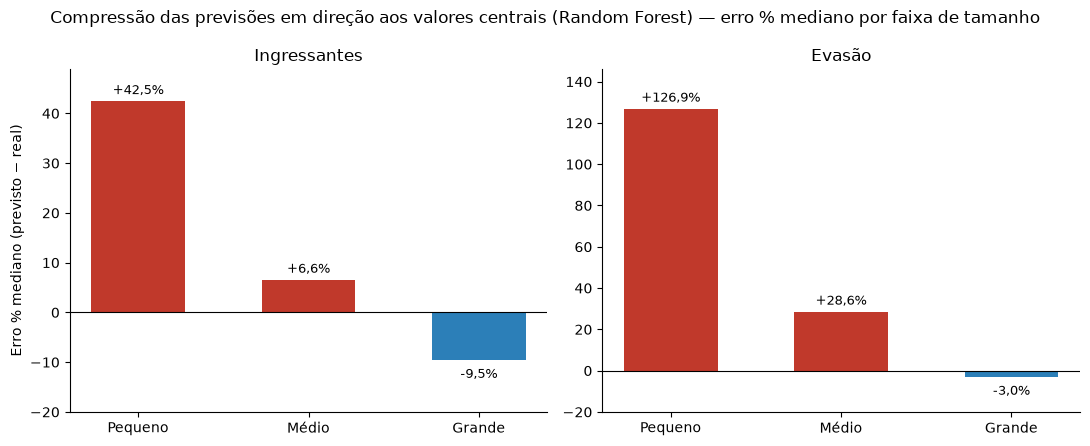

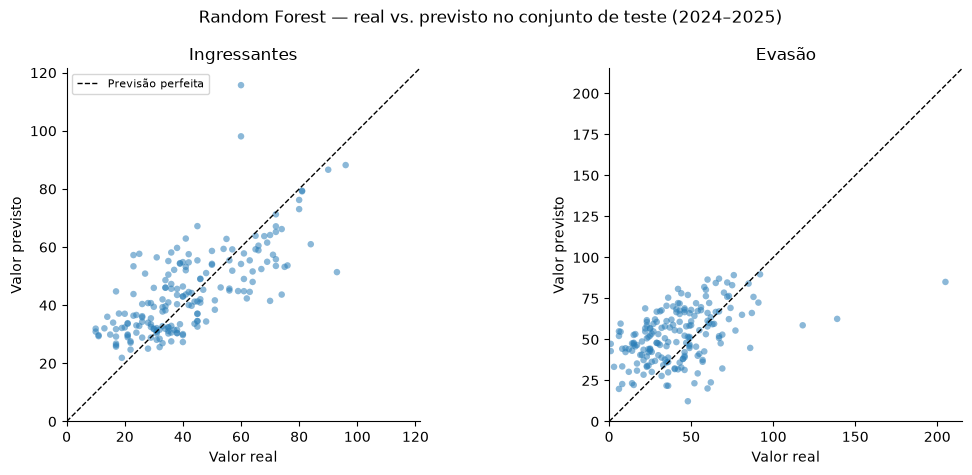

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nome_alvo, d) in zip(axes, erros.items()):
    v = d.groupby('faixa', observed=True)['erro_%'].median()
    barras = ax.bar(v.index.astype(str), v.values, color=['#c0392b' if x > 0 else '#2c7fb8' for x in v.values], width=0.55)
    ax.axhline(0, color='black', lw=0.8)
    for b, x in zip(barras, v.values):
        ax.annotate(f'{x:+.1f}%', (b.get_x() + b.get_width() / 2, x), xytext=(0, 5 if x >= 0 else -13), textcoords='offset points', ha='center', fontsize=9)
    ax.set_title(nome_alvo); ax.set_ylim(min(-20, v.min() * 1.3), v.max() * 1.15)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('Erro % mediano (previsto − real)')
fig.suptitle('Compressão das previsões em direção aos valores centrais (Random Forest) — erro % mediano por faixa de tamanho')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_vies_regressao_media.png', dpi=200, facecolor='white'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (nome_alvo, d) in zip(axes, erros.items()):
    ax.scatter(d.real, d.previsto, alpha=0.55, s=22, color='#2c7fb8', edgecolor='none')
    lim = max(d.real.max(), d.previsto.max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', lw=1, label='Previsão perfeita')
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect('equal')
    ax.set_title(nome_alvo); ax.set_xlabel('Valor real'); ax.set_ylabel('Valor previsto')
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].legend(fontsize=8)
fig.suptitle('Random Forest — real vs. previsto no conjunto de teste (2024–2025)')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_real_vs_previsto.png', dpi=200, facecolor='white'); plt.show()

## 10. Ablação de blocos de *features* — TCC, Seção 5.8

Blocos aninhados: A (histórico de ingressantes, 4) ⊂ B (+ vagas, 7) ⊂ C (+ indicadores acadêmicos, 15) ⊂ D (+ ano,
curso e categóricas, 56 = V5). Os valores da coluna "vagas originais" da seção 5.1 são os mesmos desta tabela.

R² por bloco de features


Bloco                          A (4)  B (7)  C (15)  D (56, V5)
Alvo         Modelo                                            
Ingressantes Regressão Linear  0.574  0.572   0.444       0.356
             Random Forest     0.419  0.468   0.514       0.475
             XGBoost           0.386  0.393   0.448       0.419
Evasão       Regressão Linear  0.102  0.114   0.323       0.131
             Random Forest    -0.089 -0.283   0.148      -0.008
             XGBoost          -0.187 -0.287   0.048       0.013

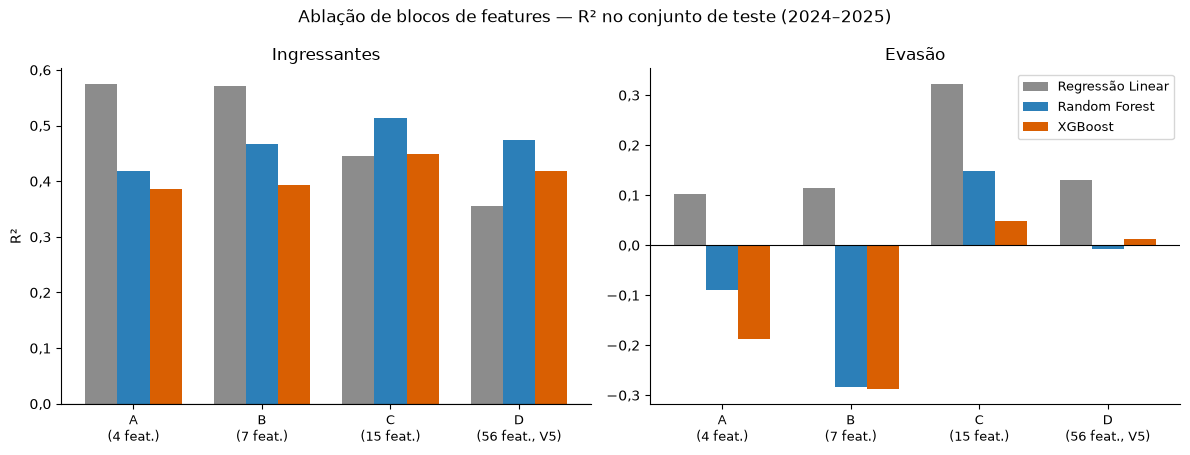

In [26]:
tab_abl = abl_orig.pivot_table(index=['Alvo', 'Modelo'], columns='Bloco', values='R²', sort=False)
print('R² por bloco de features'); display(tab_abl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
blocos_lbl = ['A\n(4 feat.)', 'B\n(7 feat.)', 'C\n(15 feat.)', 'D\n(56 feat., V5)']
x = np.arange(4); w = 0.25
for ax, nome_alvo in zip(axes, ALVOS.values()):
    for i, nome in enumerate(CORES):
        ax.bar(x + (i - 1) * w, tab_abl.loc[(nome_alvo, nome)].values, w, color=CORES[nome], label=nome)
    ax.axhline(0, color='black', lw=0.8); ax.set_xticks(x); ax.set_xticklabels(blocos_lbl, fontsize=9); ax.set_title(nome_alvo)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('R²'); axes[1].legend(fontsize=9)
fig.suptitle('Ablação de blocos de features — R² no conjunto de teste (2024–2025)')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_ablacao.png', dpi=200, facecolor='white'); plt.show()

## 11. *Walk-forward* do Bloco C — TCC, Seção 5.9

In [27]:
rc, rd = resumo(wf[wf.Bloco == 'C']), resumo(wfD)
p_ = wf.pivot_table(index=['Alvo', 'Modelo', 'Ano de teste'], columns='Bloco', values='R²', sort=False)
tab14 = pd.DataFrame({'R² médio C (excl. 2021)': rc['R² médio (excl. 2021)'], 'R² médio D (excl. 2021)': rd['R² médio (excl. 2021)']})
tab14['Δ (C − D)'] = tab14.iloc[:, 0] - tab14.iloc[:, 1]
tab14['Folds C > D (de 5)'] = (p_.C > p_.D).groupby(level=[0, 1], sort=False).sum()
display(tab14.round(3))
print('Bloco C, R² médio nos 5 folds (inclui 2021):'); display(rc['R² médio'].round(3))

R² médio C (excl. 2021)  R² médio D (excl. 2021)  Δ (C − D)  Folds C > D (de 5)
Alvo         Modelo                                                                                           
Ingressantes Regressão Linear                    0.531                    0.392      0.140                   5
             Random Forest                       0.531                    0.540     -0.009                   2
             XGBoost                             0.466                    0.497     -0.031                   1
Evasão       Regressão Linear                   -0.110                   -0.353      0.243                   3
             Random Forest                      -0.238                   -0.286      0.048                   3
             XGBoost                            -0.348                   -0.347     -0.001                   3

Bloco C, R² médio nos 5 folds (inclui 2021):


Alvo          Modelo          
Ingressantes  Regressão Linear   -1.508
              Random Forest       0.470
              XGBoost             0.358
Evasão        Regressão Linear   -0.900
              Random Forest      -0.270
              XGBoost            -0.376
Name: R² médio, dtype: float64

## 12. Teste exploratório: matrícula trancada — TCC, Seção 5.10

O indicador "Matrícula (trancada)" foi coletado no painel *IFCE em Números* e está em `Banco de Dados.xlsx`
(linhas com Tipo = "Matrícula trancada"). Ele é usado apenas neste teste: as seções anteriores não dependem dele.

In [28]:
tranc = carregar_trancada()
print(f"{tranc.groupby(['campus', 'curso', 'mod_curso', 'mod_ensino']).ngroups} ofertas com a linha 'Matrícula trancada'")
df_t = df.merge(tranc, on=['campus', 'curso', 'mod_curso', 'mod_ensino', 'ano'], how='left')
base_t, _ = construir_base(df_t)
base_t = base_t.sort_values(['oferta_id', 'ano'])
base_t['trancada_lag1'] = base_t.groupby('oferta_id')['trancada'].shift(1)
base_t['trancada_ma3'] = base_t.groupby('oferta_id')['trancada'].transform(lambda s: s.shift(1).rolling(3, min_periods=3).mean())
linhas = []
for ano_teste in range(2021, 2026):
    tr, te, _ = preparar(base_t[base_t.ano <= ano_teste - 1].copy(), base_t[base_t.ano == ano_teste].copy())
    for rotulo, cols in [('sem trancada', BLOCO_C), ('com trancada', BLOCO_C + ['trancada_lag1', 'trancada_ma3'])]:
        for nome, m in modelos().items():
            a_te, p, _, _ = ajustar_prever(m, tr, te, cols, 'evasao')
            linhas.append({'Modelo': nome, 'Versão': rotulo, 'Ano de teste': ano_teste, 'R²': r2_score(a_te.evasao, p)})
lt = pd.DataFrame(linhas)
print('R² médio para Evasão (walk-forward, excluindo 2021) — Tabela da Seção 5.10')
tab_tr = lt[lt['Ano de teste'] != 2021].pivot_table(index='Modelo', columns='Versão', values='R²')[['sem trancada', 'com trancada']]
tab_tr['Δ'] = tab_tr['com trancada'] - tab_tr['sem trancada']
display(tab_tr.round(3))
print('Incluindo 2021:'); display(lt.pivot_table(index='Modelo', columns='Versão', values='R²').round(3))
print('Por fold:'); display(lt.pivot_table(index=['Modelo', 'Versão'], columns='Ano de teste', values='R²').round(2))

139 ofertas com a linha 'Matrícula trancada'


R² médio para Evasão (walk-forward, excluindo 2021) — Tabela da Seção 5.10


Versão,sem trancada,com trancada,Δ
Modelo,,,
Random Forest,-0.238,-0.223,0.015
Regressão Linear,-0.110,-0.642,-0.532
XGBoost,-0.348,-0.292,0.056


Incluindo 2021:


Versão,com trancada,sem trancada
Modelo,,
Random Forest,-0.249,-0.270
Regressão Linear,-0.803,-0.900
XGBoost,-0.300,-0.376


Por fold:


Ano de teste                   2021  2022  2023  2024  2025
Modelo           Versão                                    
Random Forest    com trancada -0.35 -1.06  0.39  0.13 -0.35
                 sem trancada -0.39 -0.89  0.16  0.04 -0.27
Regressão Linear com trancada -1.45 -2.11  0.12 -0.30 -0.28
                 sem trancada -4.06 -0.71 -0.06  0.30  0.03
XGBoost          com trancada -0.33 -1.14  0.34  0.06 -0.42
                 sem trancada -0.49 -0.92  0.14 -0.11 -0.50

## 13. Interpretabilidade via SHAP — TCC, Seção 5.11

`shap.TreeExplainer` sobre *Random Forest* e XGBoost do modelo V5, calculado no conjunto de teste (2024–2025).

In [29]:
NOMES = {'ano': 'Ano', 'curso_enc': 'Curso (codificado)', 'ingressantes_lag1': 'Ingressantes (ano-1)',
         'ingressantes_lag2': 'Ingressantes (ano-2)', 'ingressantes_ma3': 'Ingressantes (média móvel 3 anos)',
         'ingressantes_cresc_pct': 'Crescimento de ingressantes (%)', 'evasao_lag1': 'Evasão (ano-1)',
         'evasao_ma3': 'Evasão (média móvel 3 anos)', 'matriculas_ativas_lag1': 'Matrículas ativas (ano-1)',
         'matriculas_ativas_ma3': 'Matrículas ativas (média móvel 3 anos)', 'taxa_evasao_hist': 'Taxa de evasão histórica',
         'concluintes_lag1': 'Concluintes (ano-1)', 'concluintes_ma3': 'Concluintes (média móvel 3 anos)',
         'taxa_conclusao_hist': 'Taxa de conclusão histórica', 'vagas_ofertadas_lag1': 'Vagas ofertadas (ano-1)',
         'vagas_ofertadas_ma3': 'Vagas ofertadas (média móvel 3 anos)', 'taxa_ocupacao_hist': 'Taxa de ocupação histórica'}
nome_legivel = lambda c: NOMES.get(c, c.replace('campus_', 'Campus: ').replace('mod_curso_', 'Modalidade: ').replace('area_cine_', 'Área: '))

importancias, shap_rf_evasao = {}, None
for alvo, nome_alvo in ALVOS.items():
    for nome in ['Random Forest', 'XGBoost']:
        m = modelos()[nome]
        a_te, _, m, Xte = ajustar_prever(m, TR, TE, ORDEM_TABELA, alvo)
        sv = shap.TreeExplainer(m).shap_values(Xte)
        importancias[(nome_alvo, nome)] = pd.Series(np.abs(sv).mean(0), index=ORDEM_TABELA)
        if alvo == 'evasao' and nome == 'Random Forest':
            shap_rf_evasao, X_shap = sv, Xte
tab_shap = pd.DataFrame(importancias)
top = sorted(set().union(*[tab_shap[c].nlargest(6).index for c in tab_shap.columns]), key=lambda c: -tab_shap.loc[c].max())
print('Média de |SHAP| (features entre as 6 maiores de algum alvo/modelo)')
display(tab_shap.loc[top].rename(index=nome_legivel).round(2))

Média de |SHAP| (features entre as 6 maiores de algum alvo/modelo)


Ingressantes                Evasão        
                                       Random Forest XGBoost Random Forest XGBoost
Ano                                             0.41    1.24         12.40   12.08
Ingressantes (média móvel 3 anos)               7.50    4.71          2.04    3.01
Matrículas ativas (média móvel 3 anos)          0.77    1.49          3.00    5.66
Evasão (média móvel 3 anos)                     0.36    1.18          3.40    2.07
Matrículas ativas (ano-1)                       2.54    3.11          0.37    1.76
Evasão (ano-1)                                  0.49    0.56          3.11    2.08
Curso (codificado)                              2.45    2.88          0.46    1.15
Campus: Fortaleza                               0.35    0.62          1.97    2.06
Vagas ofertadas (ano-1)                         0.46    1.20          1.18    1.97
Vagas ofertadas (média móvel 3 anos)            0.84    1.00          0.70    0.93
Ingressantes (ano-1)                            0.81    0.63          0.47    0.54

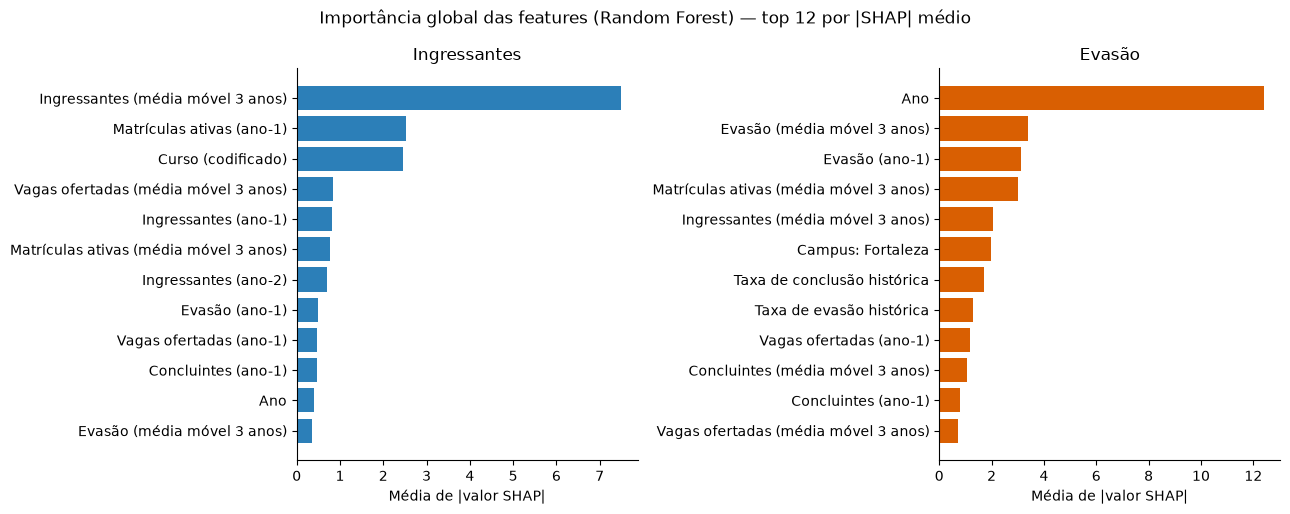

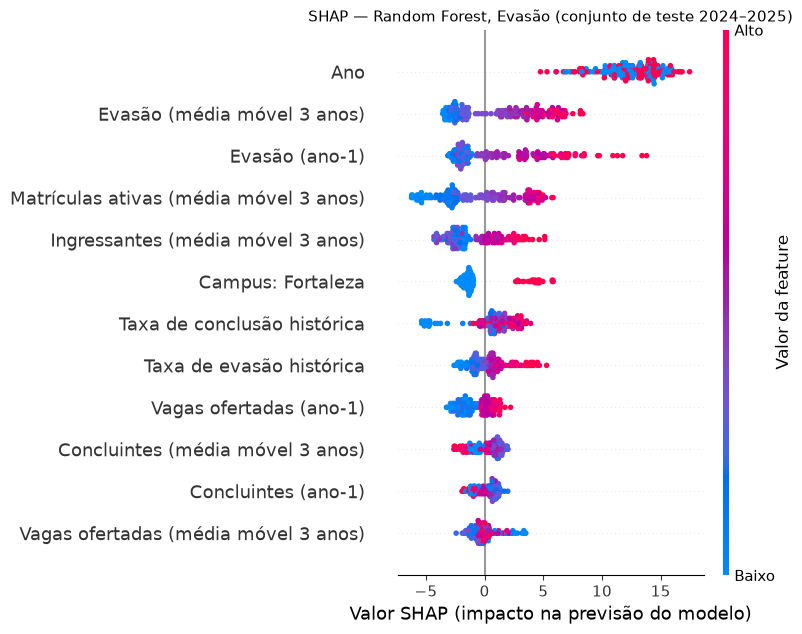

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, nome_alvo, cor in zip(axes, ALVOS.values(), ['#2c7fb8', '#d95f02']):
    s = importancias[(nome_alvo, 'Random Forest')].nlargest(12)[::-1]
    ax.barh([nome_legivel(c) for c in s.index], s.values, color=cor)
    ax.set_title(nome_alvo); ax.set_xlabel('Média de |valor SHAP|')
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
fig.suptitle('Importância global das features (Random Forest) — top 12 por |SHAP| médio')
fig.tight_layout(); aplicar_br(fig); fig.savefig(f'{PASTA_FIG}/fig_shap_importancia.png', dpi=200, facecolor='white'); plt.show()

plt.figure()
shap.summary_plot(shap_rf_evasao, X_shap.rename(columns=nome_legivel), max_display=12, show=False)
plt.title('SHAP — Random Forest, Evasão (conjunto de teste 2024–2025)', fontsize=11)
_f = plt.gcf()
_f.axes[0].set_xlabel('Valor SHAP (impacto na previsão do modelo)')
if len(_f.axes) > 1:
    _cb = _f.axes[-1]; _cb.set_ylabel('Valor da feature')
    _cb.set_yticks(_cb.get_yticks()); _cb.set_yticklabels(['Baixo' if l.get_text() == 'Low' else 'Alto' if l.get_text() == 'High' else l.get_text() for l in _cb.get_yticklabels()])
aplicar_br(_f)
plt.savefig(f'{PASTA_FIG}/fig_shap_beeswarm_evasao.png', dpi=200, bbox_inches='tight', facecolor='white'); plt.show()

## 14. Nota de transparência: ordem das colunas

A ordem das colunas não muda o conjunto de variáveis nem a especificação do modelo, mas muda o desempate interno dos
sorteios do *Random Forest* e do XGBoost. As análises do TCC foram produzidas em duas execuções que usaram ordens
diferentes; para reproduzir cada número exatamente, este notebook usa a mesma ordem de cada execução original. A
tabela abaixo mostra que a diferença entre as duas ordens é pequena (no máximo cerca de 0,02 no R²) e não altera
nenhuma conclusão; a Regressão Linear não é afetada.

In [31]:
comp = []
for rotulo, cols in [('Ordem da Tabela V5 / ablação / SHAP', ORDEM_TABELA), ('Ordem do walk-forward / erros / projeção', ORDEM_NOTEBOOK)]:
    for alvo, nome_alvo in ALVOS.items():
        for nome, m in modelos().items():
            a_te, p, _, _ = ajustar_prever(m, TR, TE, cols, alvo)
            comp.append({'Ordem': rotulo, 'Alvo': nome_alvo, 'Modelo': nome, 'R²': r2_score(a_te[alvo], p)})
display(pd.DataFrame(comp).pivot_table(index=['Alvo', 'Modelo'], columns='Ordem', values='R²', sort=False).round(3))

Ordem                          Ordem da Tabela V5 / ablação / SHAP  Ordem do walk-forward / erros / projeção
Alvo         Modelo                                                                                         
Ingressantes Regressão Linear                                0.356                                     0.356
             Random Forest                                   0.475                                     0.477
             XGBoost                                         0.419                                     0.400
Evasão       Regressão Linear                                0.131                                     0.131
             Random Forest                                  -0.008                                    -0.004
             XGBoost                                         0.013                                     0.016

## 15. Download das figuras

In [32]:
with zipfile.ZipFile('figuras_tcc.zip', 'w') as z:
    for arq in sorted(os.listdir(PASTA_FIG)):
        z.write(os.path.join(PASTA_FIG, arq), arq)
print('Figuras geradas:', sorted(os.listdir(PASTA_FIG)))
try:
    from google.colab import files
    files.download('figuras_tcc.zip')
except ImportError:
    print('Arquivo figuras_tcc.zip salvo na pasta atual.')

Figuras geradas: ['fig_ablacao.png', 'fig_baselines.png', 'fig_evasao_covid.png', 'fig_evasao_ingressantes.png', 'fig_horizonte.png', 'fig_ocupacao_vagas.png', 'fig_previsao_aracati.png', 'fig_previsao_melhores_ofertas.png', 'fig_r2_v5.png', 'fig_real_vs_previsto.png', 'fig_shap_beeswarm_evasao.png', 'fig_shap_importancia.png', 'fig_vies_regressao_media.png', 'fig_walk_forward.png']
Arquivo figuras_tcc.zip salvo na pasta atual.
